In [35]:
import pandas as pd

# Read Excel file
df = pd.read_excel("latest_transactions.xlsx", sheet_name=0, skiprows=8)

In [36]:
#rename column names
df = df.rename(columns={
    '거래 일시': 'Date',
    '적요': 'Remarks',
    '거래 유형': 'Transaction_Type',
    '거래 기관': 'Bank_Name',
    '계좌번호': 'Account_Number',
    '거래 금액': 'Transaction_Amount',
    '거래 후 잔액': 'Balance',
    '메모': 'Memo'
})

# drop columns
df = df.drop(columns=['Unnamed: 0', 'Memo'])

# fill na with 0 and convert to int
df["Account_Number"] = df["Account_Number"].fillna(0).astype(int)

In [37]:
#translate transaction_type column to english
df['Transaction_Type'] = df['Transaction_Type'].replace({
    '체크카드결제': 'Check Card',
    '입금': 'Deposit',
    '출금': 'Withdrawal',
    '프로모션입금': 'Cashback',
    '오픈뱅킹': 'Open Banking',
    '이자입금': 'Interest Deposit',
    'ATM출금': 'ATM Withdrawal',
    'BC카드': 'ATM Deposit'
})

In [38]:
df['Date'] = pd.to_datetime(df['Date'], format='%Y.%m.%d %H:%M:%S')

df['Time'] = df['Date'].dt.time
df['Date'] = df['Date'].dt.date

# Reorder
df = df[['Date', 'Time'] + [col for col in df.columns if col not in ['Date', 'Time']]]

# Save to csv
df.to_csv('transactions.csv', index=False, encoding="utf-8")

In [39]:
import pandas as pd

df = pd.read_csv('transactions.csv')
df.head(10)

,Date,Time,Remarks,Transaction_Type,Bank_Name,Account_Number,Transaction_Amount,Balance
0,2025-09-26,17:35:42,카드 캐시백,Cashback,NaN,0,100,115514.0
1,2025-09-26,16:10:53,이마트24 인하대도서관점,Check Card,NaN,0,-2300,115414.0
2,2025-09-26,14:47:39,BAKTYBEK UULU ARSEN,Withdrawal,토스뱅크,100082135836,-2000,117714.0
3,2025-09-26,14:45:35,무르타저인하대학교,Withdrawal,하나은행,17796620828237,-2755000,119714.0
4,2025-09-26,14:31:56,ATM입금,KB국민은행,NaN,0,100000,2874714.0
5,2025-09-26,13:51:14,TOSHNIYOZO,Deposit,하나은행,0,13500,2774714.0
6,2025-09-26,13:49:59,TOSHNIYOZO,Deposit,하나은행,0,760000,2761214.0
7,2025-09-26,13:49:30,TOSHNIYOZO,Deposit,하나은행,0,2000000,2001214.0
8,2025-09-26,13:47:13,TOSHNIYOZO,Withdrawal,하나은행,74891139488007,-2775000,1214.0
9,2025-09-26,13:43:49,취소 무르타저인하대학교,Deposit,NaN,0,2775000,2776214.0


In [40]:
import pandas as pd

df = pd.read_csv('transactions.csv')
df.to_excel("formatted_transactions.xlsx", index=False)

In [41]:
import pandas as pd

df = pd.read_csv('transactions.csv')

def total_by_unique_remarks(df, name):
    mask = df['Remarks'].str.contains(name, na=False, case=False)
    total_spent = df.loc[mask, 'Transaction_Amount'].sum()
    print(f"Total spent at {name}:", total_spent)

# total_by_unique_remarks(tr, '페이브')
# total_by_unique_remarks(tr, '카드 캐시백')
# total_by_unique_remarks(df, '통장 이자')
# total_by_unique_remarks(df, '김용채')
# total_by_unique_remarks(df, '이마트24')
# total_by_unique_remarks(df, '스마일마트')
# total_by_unique_remarks(df, '셔호나')
# total_by_unique_remarks(df, 'SENTBE')
# total_by_unique_remarks(df, '나우커피 인하대점')
# total_by_unique_remarks(df, '건강TOSHNIYO')
# total_by_unique_remarks(df, 'TOSHNIYO')
# total_by_unique_remarks(df, 'CU')

In [42]:
def column_value_counts(df, name):
    print(df[name].value_counts())
    
column_value_counts(df, 'Transaction_Type')

Transaction_Type
Check Card          310
Deposit             135
Withdrawal          110
Cashback             49
Open Banking          6
Interest Deposit      5
ATM Withdrawal        3
KB국민은행                1
ATM Deposit           1
Name: count, dtype: int64


In [43]:
def individual_transactions(name):
    mask = df['Remarks'].str.contains(name, na=False, case=False)
    # transactions_of_individual = df[mask]   
    # Calculate totals by Remarks type
    withdrawal_mask = mask & (df['Transaction_Type'] == 'Withdrawal')
    deposit_mask = mask & (df['Transaction_Type'] == 'Deposit')

    total_withdrawal = df.loc[withdrawal_mask, 'Transaction_Amount'].sum()
    total_deposit = df.loc[deposit_mask, 'Transaction_Amount'].sum()

    print(f'\n{name} Summary:')
    # print(transactions_of_individual[['Date', 'Transaction_Type', 'Transaction_Amount', 'Bank_Name']])
    print(f'Withdrawals: {total_withdrawal} KRW ({withdrawal_mask.sum()} transactions)')
    print(f'Deposits: {total_deposit} KRW ({deposit_mask.sum()} transactions)')
    print(f'Net amount: {total_deposit - total_withdrawal} KRW')
    
individual_transactions('ABDUKARIMOV HUMOYUNBEK')
# individual_transactions('KURBONALIE')
# individual_transactions('MUNTOXIROV')
# individual_transactions('NAJIMOV OTABEK')
# individual_transactions('KIYOMOV')
# individual_transactions('ISMAILOV')


ABDUKARIMOV HUMOYUNBEK Summary:
Withdrawals: -252000 KRW (11 transactions)
Deposits: 1915334 KRW (14 transactions)
Net amount: 2167334 KRW


=== CASH FLOW CORE KPIs ===
Total Income: 26,620,941 KRW
Total Expenses: 26,673,929 KRW
Net Flow: -52,988 KRW
Savings Rate: -0.2%

=== MONTHLY TRENDS ===
2025-04: Income 886,348 KRW | Expenses 885,350 KRW | Net 998 KRW
2025-05: Income 1,090,799 KRW | Expenses 941,402 KRW | Net 149,397 KRW
2025-06: Income 3,230,738 KRW | Expenses 3,341,155 KRW | Net -110,417 KRW
2025-07: Income 4,370,976 KRW | Expenses 4,029,420 KRW | Net 341,556 KRW
2025-08: Income 2,154,890 KRW | Expenses 2,556,904 KRW | Net -402,014 KRW
2025-09: Income 14,887,190 KRW | Expenses 14,919,698 KRW | Net -32,508 KRW


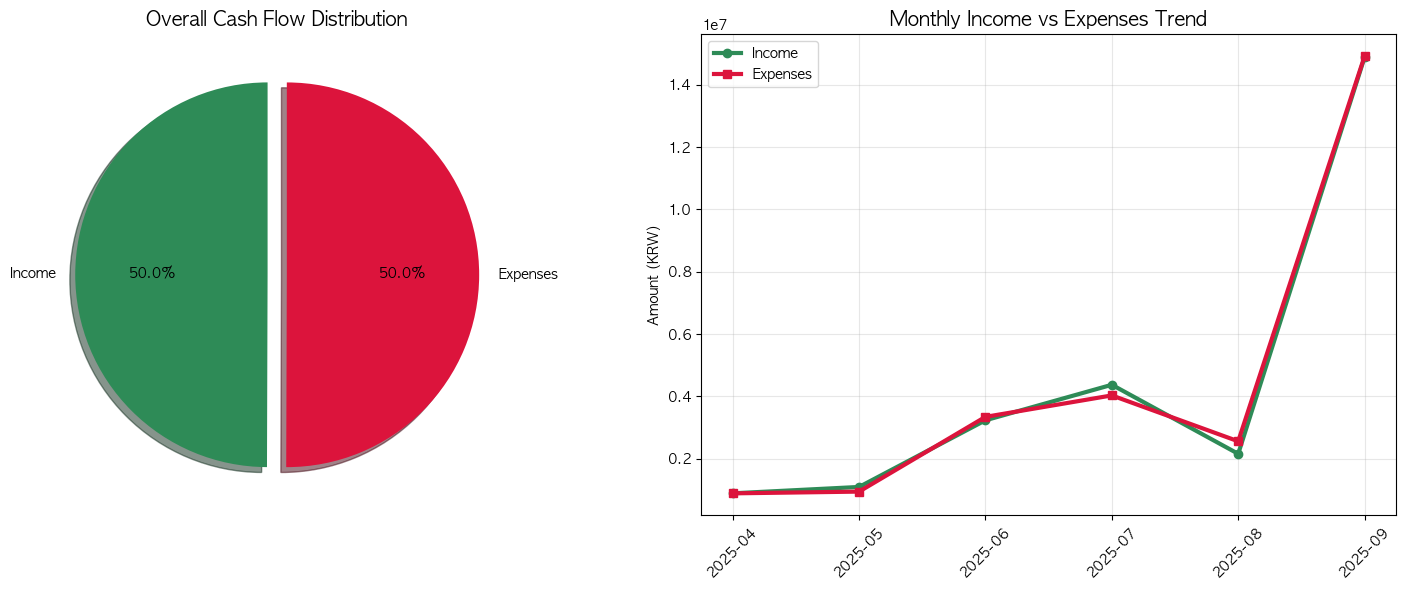


✅ Dashboard saved as 'cash_flow_kpis_dashboard.png'


In [44]:
import matplotlib.pyplot as plt
import pandas as pd

df = pd.read_csv('transactions.csv')

# Parse date and create month column
df['DateTime'] = pd.to_datetime(df['Date'] + ' ' + df['Time'])
df['Month'] = df['DateTime'].dt.to_period('M')

# 1) Cash Flow Core KPIs
# Categorize transactions
income_types = ['Deposit', 'Cashback', 'Interest Deposit']
expense_types = ['Withdrawal', 'Check Card', 'ATM Withdrawal']

income_data = df[df['Transaction_Type'].isin(income_types)]
expense_data = df[df['Transaction_Type'].isin(expense_types)]

# Calculate totals
total_income = income_data['Transaction_Amount'].sum()
total_expenses = abs(expense_data['Transaction_Amount'].sum())  # Make positive
net_flow = total_income - total_expenses

print("=== CASH FLOW CORE KPIs ===")
print(f"Total Income: {total_income:,.0f} KRW")
print(f"Total Expenses: {total_expenses:,.0f} KRW") 
print(f"Net Flow: {net_flow:,.0f} KRW")
print(f"Savings Rate: {(net_flow/total_income)*100:.1f}%")

# 2) Monthly Trends
monthly_income = income_data.groupby('Month')['Transaction_Amount'].sum()
monthly_expenses = expense_data.groupby('Month')['Transaction_Amount'].sum().abs()
monthly_net = monthly_income - monthly_expenses

print("\n=== MONTHLY TRENDS ===")
for month in monthly_income.index:
    income = monthly_income.get(month, 0)
    expenses = monthly_expenses.get(month, 0)
    net = income - expenses
    print(f"{month}: Income {income:,.0f} KRW | Expenses {expenses:,.0f} KRW | Net {net:,.0f} KRW")

# Dashboard Visualization
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))

# 1) Overall Cash Flow Pie Chart
sizes = [total_income, total_expenses]
labels = ['Income', 'Expenses']
colors = ['#2E8B57', '#DC143C']
explode = (0.05, 0.05)

ax1.pie(sizes, labels=labels, colors=colors, autopct='%1.1f%%', 
        startangle=90, explode=explode, shadow=True)
ax1.set_title('Overall Cash Flow Distribution', fontsize=14, fontweight='bold')

# 2) Monthly Trend Line Chart
months = [str(m) for m in monthly_income.index]
ax2.plot(months, monthly_income.values, marker='o', linewidth=3, 
         label='Income', color='#2E8B57')
ax2.plot(months, monthly_expenses.values, marker='s', linewidth=3, 
         label='Expenses', color='#DC143C')
ax2.set_title('Monthly Income vs Expenses Trend', fontsize=14, fontweight='bold')
ax2.set_ylabel('Amount (KRW)')
ax2.legend()
ax2.grid(True, alpha=0.3)
ax2.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.savefig('visuals/cash_flow_kpis_dashboard.png', dpi=300, bbox_inches='tight')
plt.show()

print("\n✅ Dashboard saved as 'cash_flow_kpis_dashboard.png'")

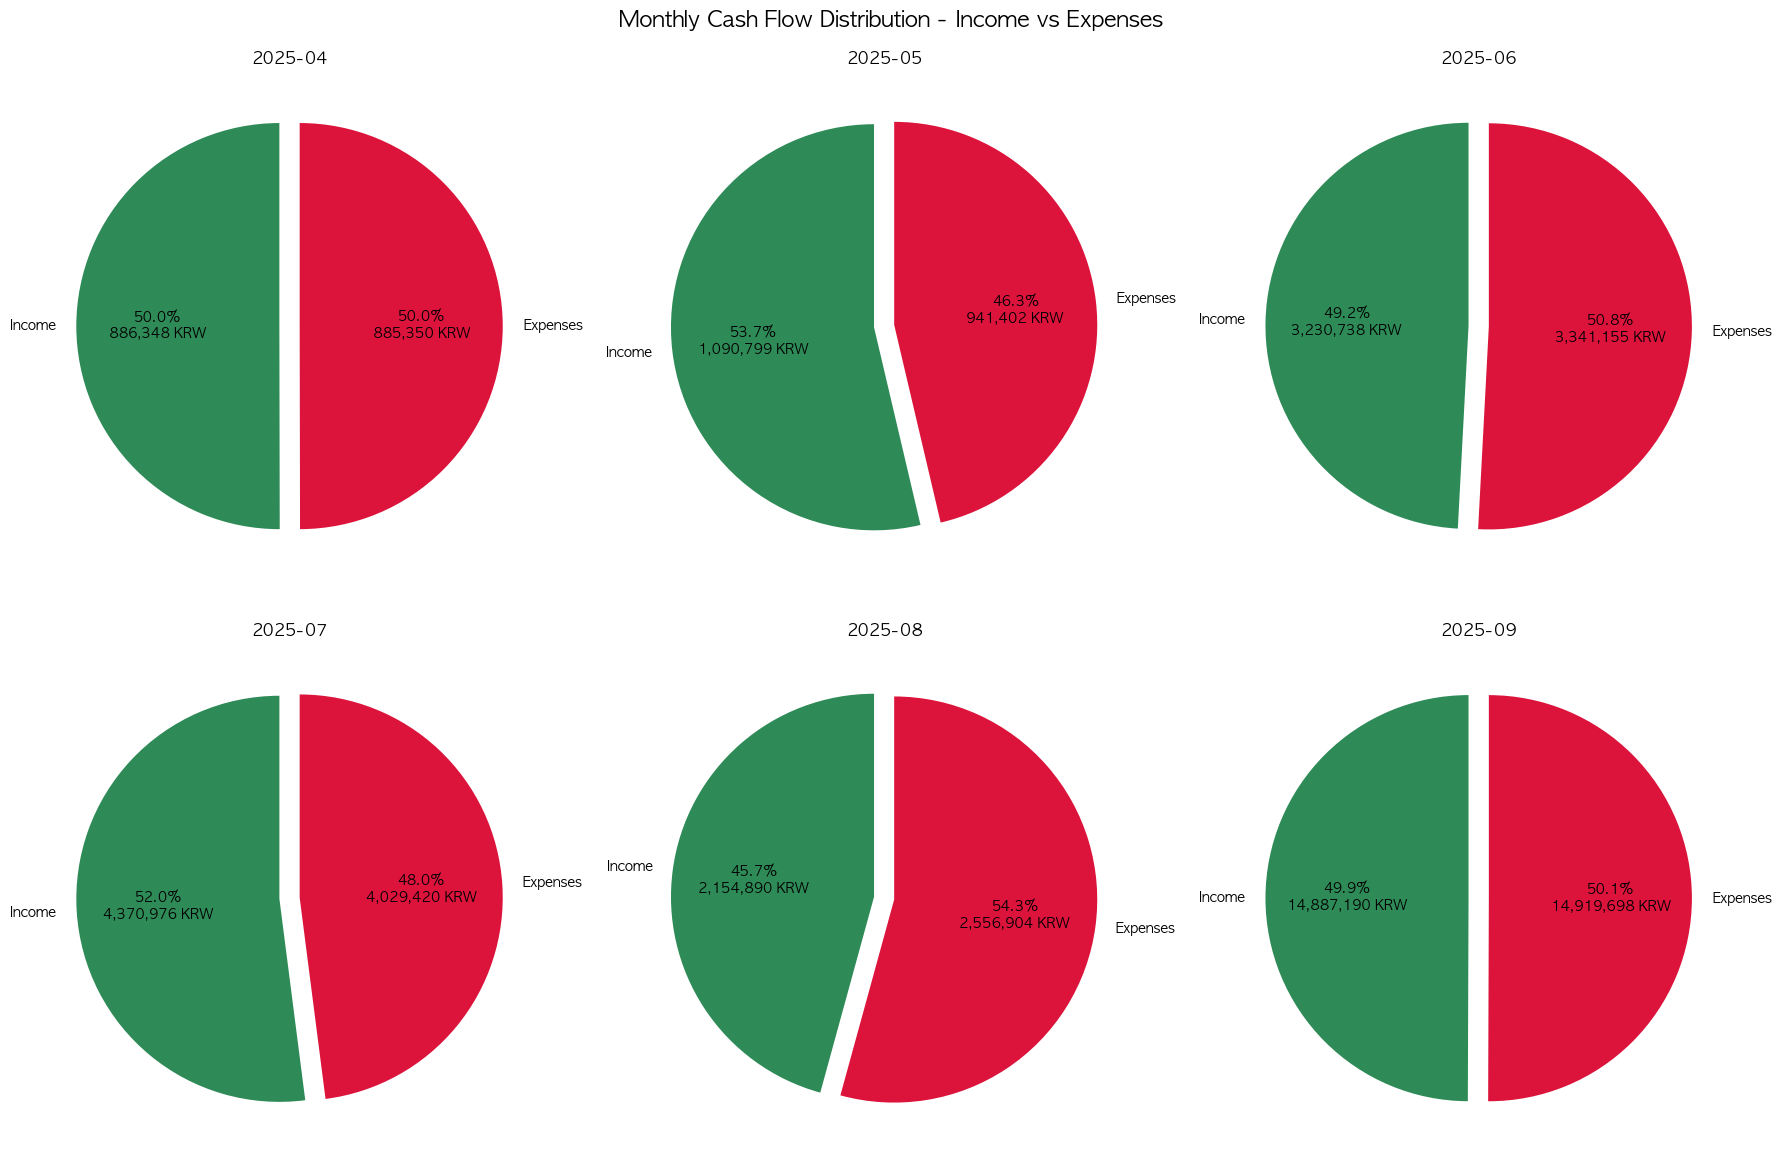

✅ Monthly Cash Flow Breakdown saved as 'monthly_cash_flow_breakdown.png'

=== MONTHLY BREAKDOWN SUMMARY ===
2025-04: Income 886,348 KRW | Expenses 885,350 KRW | Net 998 KRW
2025-05: Income 1,090,799 KRW | Expenses 941,402 KRW | Net 149,397 KRW
2025-06: Income 3,230,738 KRW | Expenses 3,341,155 KRW | Net -110,417 KRW
2025-07: Income 4,370,976 KRW | Expenses 4,029,420 KRW | Net 341,556 KRW
2025-08: Income 2,154,890 KRW | Expenses 2,556,904 KRW | Net -402,014 KRW
2025-09: Income 14,887,190 KRW | Expenses 14,919,698 KRW | Net -32,508 KRW


In [45]:
import matplotlib.pyplot as plt
import pandas as pd

df = pd.read_csv('transactions.csv')

# Parse date and create month column
df['DateTime'] = pd.to_datetime(df['Date'] + ' ' + df['Time'])
df['Month'] = df['DateTime'].dt.to_period('M')

# Categorize transactions
income_types = ['Deposit', 'Cashback', 'Interest Deposit']
expense_types = ['Withdrawal', 'Check Card', 'ATM Withdrawal']

income_data = df[df['Transaction_Type'].isin(income_types)]
expense_data = df[df['Transaction_Type'].isin(expense_types)]

# Calculate monthly totals
monthly_income = income_data.groupby('Month')['Transaction_Amount'].sum()
monthly_expenses = expense_data.groupby('Month')['Transaction_Amount'].sum().abs()

# Create custom autopct function to show both percentage and amount
def autopct_format(values):
    def inner_autopct(pct):
        total = sum(values)
        val = int(round(pct * total / 100.0))
        return f"{pct:.1f}%\n{val:,.0f} KRW"
    return inner_autopct

# Create subplots for each month
months = monthly_income.index
n_months = len(months)
cols = 3
rows = (n_months + cols - 1) // cols

fig, axes = plt.subplots(rows, cols, figsize=(18, 6*rows))
fig.suptitle('Monthly Cash Flow Distribution - Income vs Expenses', fontsize=16, fontweight='bold')

if rows == 1:
    axes = [axes] if n_months == 1 else axes
else:
    axes = axes.flatten()

colors = ['#2E8B57', '#DC143C']  # Green for income, Red for expenses
labels = ['Income', 'Expenses']

for i, month in enumerate(months):
    income = monthly_income.get(month, 0)
    expenses = monthly_expenses.get(month, 0)
    
    if income > 0 or expenses > 0:
        sizes = [income, expenses]
        
        # Create pie chart with amounts
        wedges, texts, autotexts = axes[i].pie(
            sizes, 
            labels=labels, 
            colors=colors,
            autopct=autopct_format(sizes),
            startangle=90,
            explode=(0.05, 0.05)
        )
        
        # Style the text
        for autotext in autotexts:
            autotext.set_fontsize(10)
            autotext.set_fontweight('bold')
            
        axes[i].set_title(f'{month}', fontweight='bold', fontsize=12)
    else:
        axes[i].text(0.5, 0.5, 'No Data', ha='center', va='center', 
                    transform=axes[i].transAxes, fontsize=12)
        axes[i].set_title(f'{month}', fontweight='bold', fontsize=12)

# Hide unused subplots
for i in range(n_months, len(axes)):
    axes[i].set_visible(False)

plt.tight_layout()
plt.savefig('visuals/monthly_cash_flow_breakdown.png', dpi=300, bbox_inches='tight', facecolor='white')
plt.show()

print("✅ Monthly Cash Flow Breakdown saved as 'monthly_cash_flow_breakdown.png'")

# Print summary
print("\n=== MONTHLY BREAKDOWN SUMMARY ===")
for month in months:
    income = monthly_income.get(month, 0)
    expenses = monthly_expenses.get(month, 0)
    net = income - expenses
    print(f"{month}: Income {income:,.0f} KRW | Expenses {expenses:,.0f} KRW | Net {net:,.0f} KRW")

=== TRANSACTION TYPE BREAKDOWN ===
                  Count  Total_Amount  Average_Amount  Median_Amount  \
Transaction_Type                                                       
Deposit             135      26615211        197150.0        87000.0   
Withdrawal          110     -24981937       -227109.0       -21000.0   
Check Card          310      -1611992         -5200.0        -2450.0   
KB국민은행                1        100000        100000.0       100000.0   
ATM Deposit           1         90000         90000.0        90000.0   
ATM Withdrawal        3        -80000        -26667.0       -20000.0   
Open Banking          6        -21498         -3583.0        -4000.0   
Cashback             49          5300           108.0          100.0   
Interest Deposit      5           430            86.0           69.0   

                  Volume_Share_%  Value_Share_%  
Transaction_Type                                 
Deposit                     21.8           49.7  
Withdrawal            

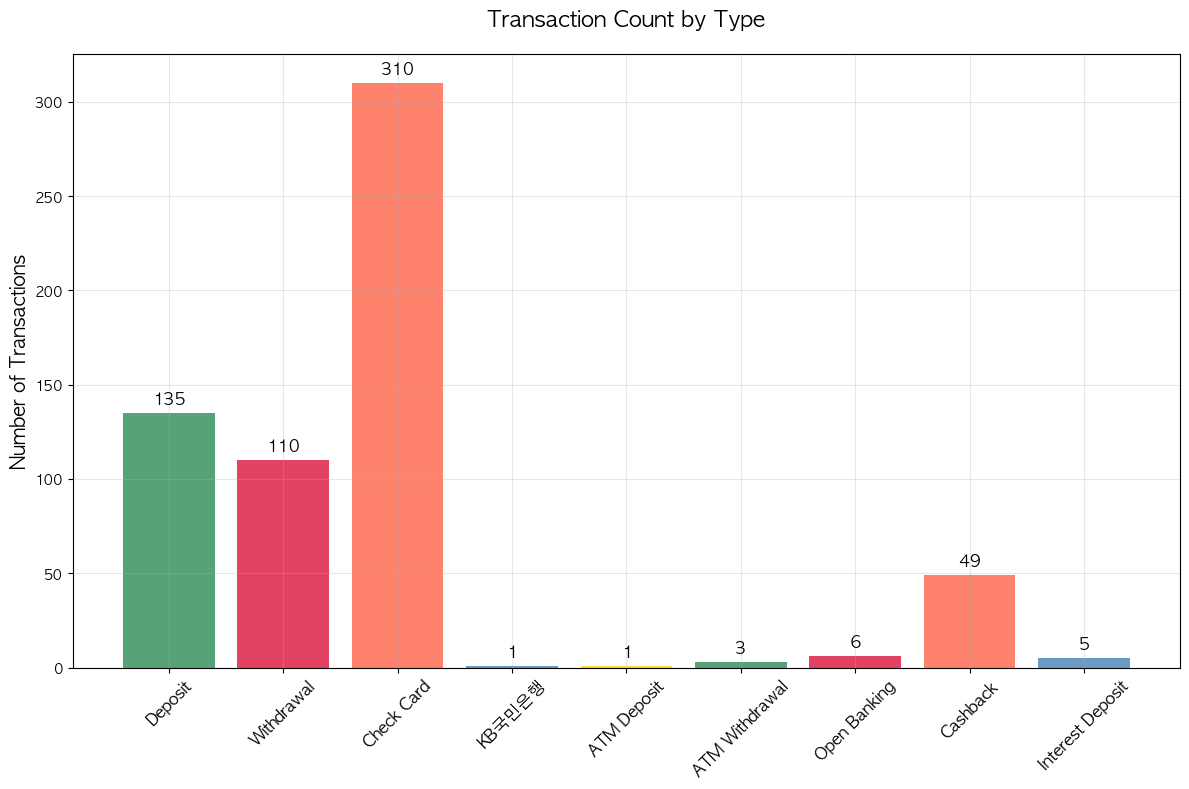

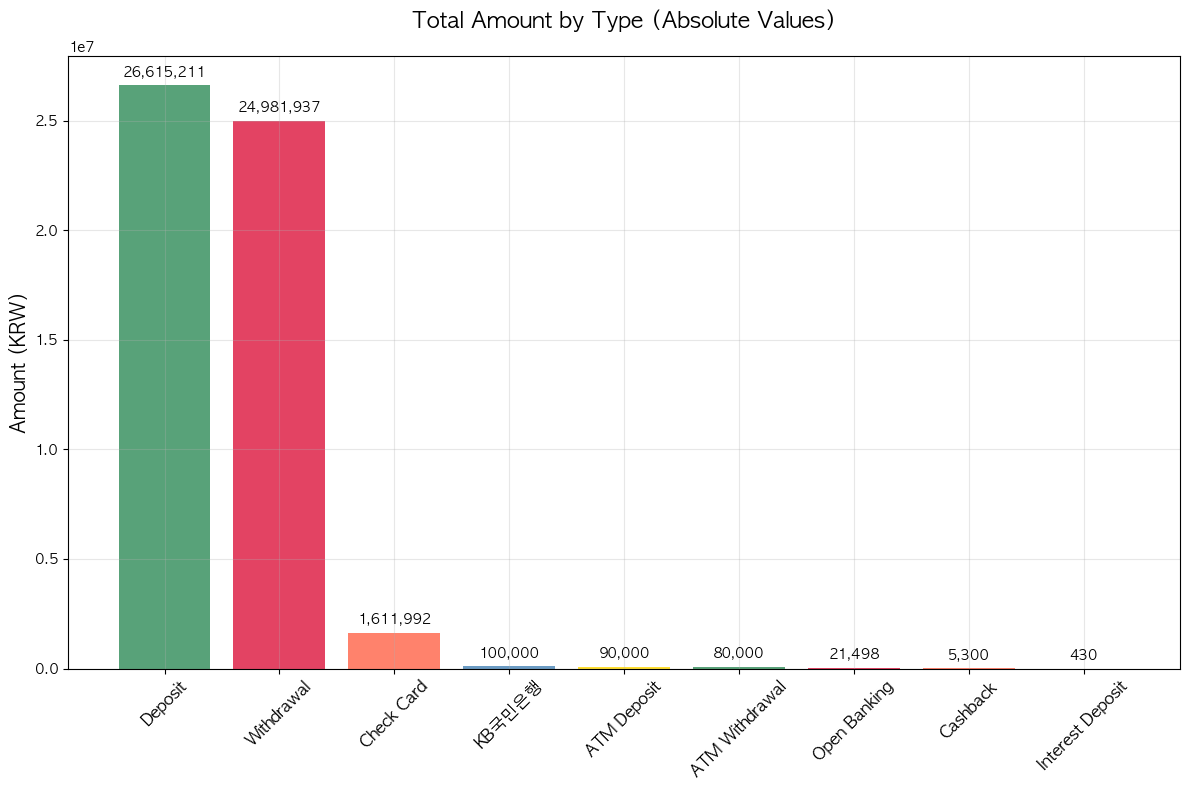

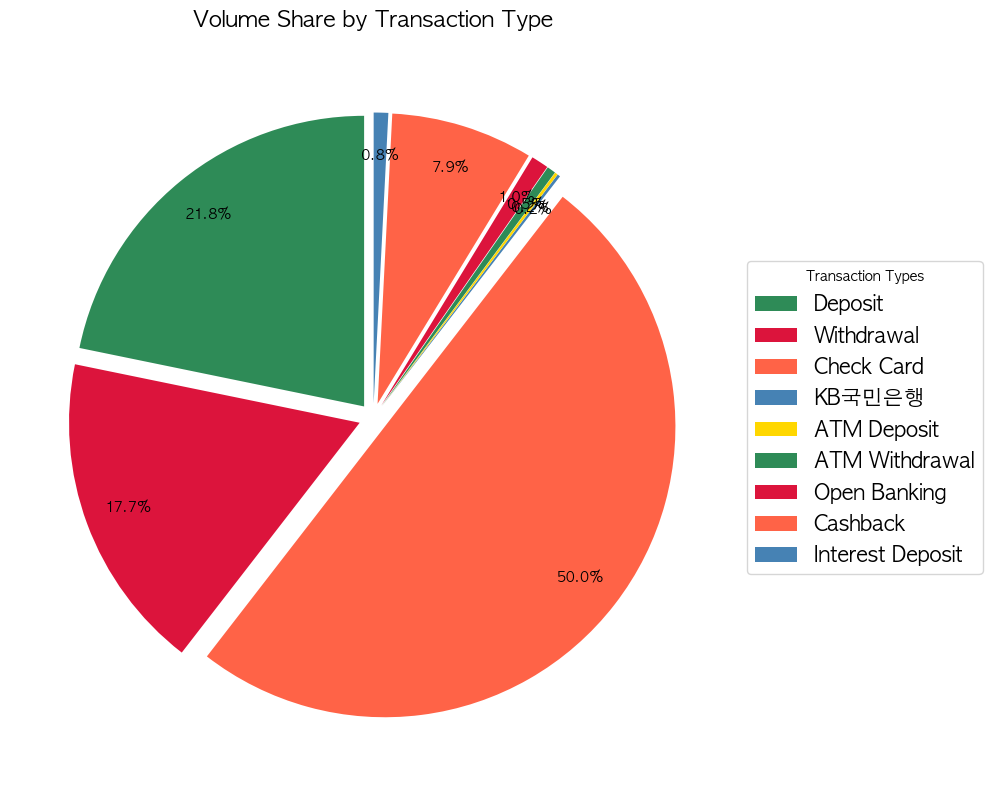


✅ Four separate charts saved:
1. transaction_count_by_type.png
2. total_amount_by_type.png
3. volume_share_pie_chart.png


In [46]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv('transactions.csv')

# Parse date and create month column
df['DateTime'] = pd.to_datetime(df['Date'] + ' ' + df['Time'])
df['Transaction_Amount'] = pd.to_numeric(df['Transaction_Amount'])

# Transaction-Type Breakdown Analysis
transaction_stats = df.groupby('Transaction_Type').agg({
    'Transaction_Amount': ['count', 'sum', 'mean', 'median']
}).round(0)

# Flatten column names
transaction_stats.columns = ['Count', 'Total_Amount', 'Average_Amount', 'Median_Amount']

# Calculate percentages
total_transactions = df.shape[0]
total_volume = df['Transaction_Amount'].abs().sum()

transaction_stats['Volume_Share_%'] = (transaction_stats['Count'] / total_transactions * 100).round(1)
transaction_stats['Value_Share_%'] = (transaction_stats['Total_Amount'].abs() / total_volume * 100).round(1)

# Sort by total amount (absolute value)
transaction_stats = transaction_stats.reindex(
    transaction_stats['Total_Amount'].abs().sort_values(ascending=False).index
)

print("=== TRANSACTION TYPE BREAKDOWN ===")
print(transaction_stats)

colors = ['#2E8B57', '#DC143C', '#FF6347', '#4682B4', '#FFD700']

# Plot 1: Transaction Count by Type
plt.figure(figsize=(12, 8))
bars = plt.bar(transaction_stats.index, transaction_stats['Count'], color=colors, alpha=0.8)
plt.title('Transaction Count by Type', fontsize=16, fontweight='bold', pad=20)
plt.ylabel('Number of Transactions', fontsize=14)
plt.xticks(rotation=45, fontsize=12)
plt.grid(True, alpha=0.3)

# Add value labels on bars
for i, v in enumerate(transaction_stats['Count']):
    plt.text(i, v + max(transaction_stats['Count'])*0.01, str(int(v)), 
             ha='center', va='bottom', fontweight='bold', fontsize=12)

plt.tight_layout()
plt.savefig('visuals/transaction_count_by_type.png', dpi=300, bbox_inches='tight', facecolor='white')
plt.show()

# Plot 2: Total Amount by Type
plt.figure(figsize=(12, 8))
abs_amounts = transaction_stats['Total_Amount'].abs()
bars = plt.bar(transaction_stats.index, abs_amounts, color=colors, alpha=0.8)
plt.title('Total Amount by Type (Absolute Values)', fontsize=16, fontweight='bold', pad=20)
plt.ylabel('Amount (KRW)', fontsize=14)
plt.xticks(rotation=45, fontsize=12)
plt.grid(True, alpha=0.3)

# Add value labels
for i, v in enumerate(abs_amounts):
    plt.text(i, v + max(abs_amounts)*0.01, f'{int(v):,}', 
             ha='center', va='bottom', fontweight='bold', fontsize=10)

plt.tight_layout()
plt.savefig('visuals/total_amount_by_type.png', dpi=300, bbox_inches='tight', facecolor='white')
plt.show()

# Plot 3: Volume Share Pie Chart
plt.figure(figsize=(10, 10))
plt.pie(transaction_stats['Count'], labels=None, autopct='%1.1f%%', colors=colors, startangle=90, explode=[0.05]*len(transaction_stats), pctdistance=0.85)
plt.legend(
    transaction_stats.index, 
    title="Transaction Types", 
    loc="center left", 
    bbox_to_anchor=(1, 0, 0.5, 1),  # move legend outside
    fontsize=15
)

# Make percentage text bold and larger
for autotext in autotexts:
    autotext.set_fontweight('bold')
    autotext.set_fontsize(14)

plt.title('Volume Share by Transaction Type', fontsize=16, fontweight='bold', pad=20)
plt.tight_layout()
plt.savefig('visuals/volume_share_pie_chart.png', dpi=300, bbox_inches='tight', facecolor='white')
plt.show()

print("\n✅ Four separate charts saved:")
print("1. transaction_count_by_type.png")
print("2. total_amount_by_type.png") 
print("3. volume_share_pie_chart.png")

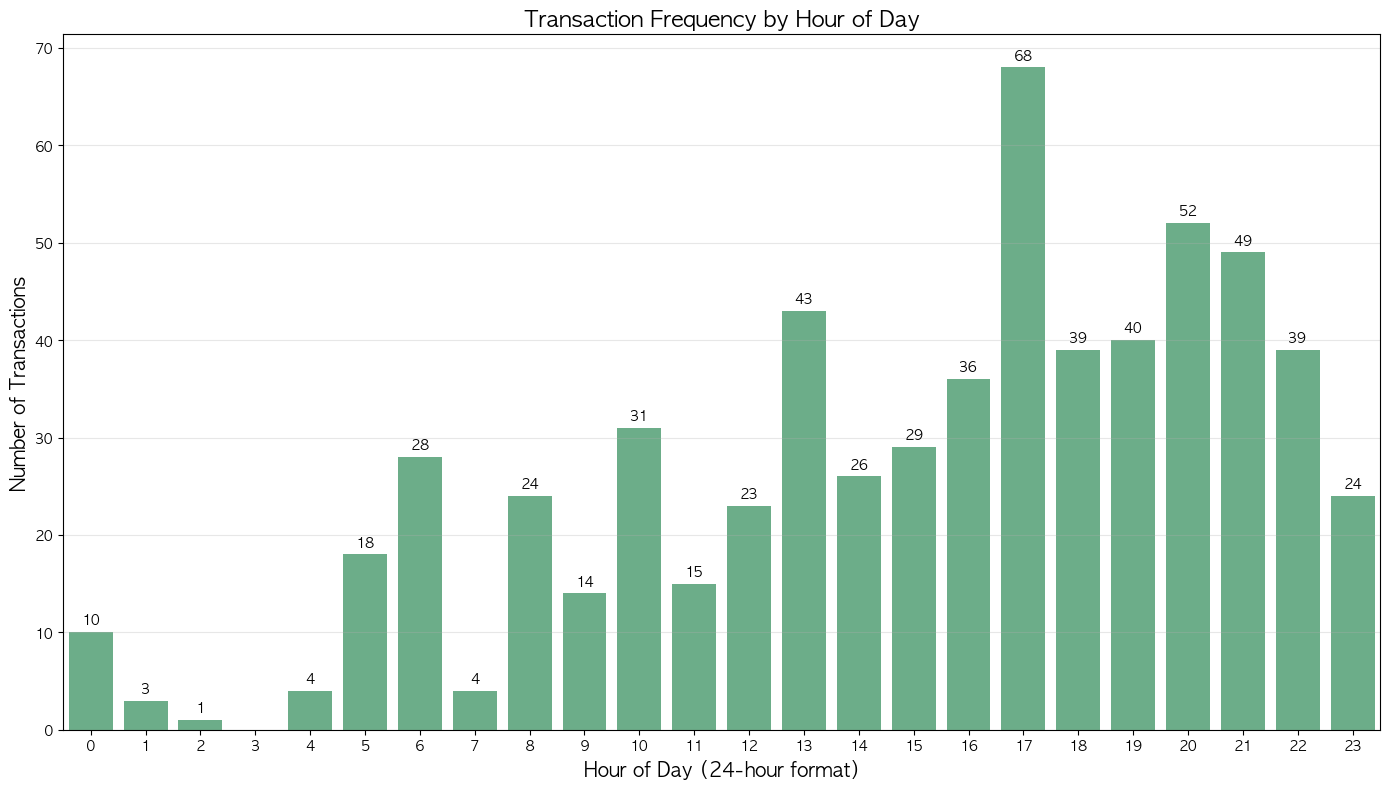

In [47]:
import pandas as pd
import matplotlib.pyplot as plt

# Read the data
df = pd.read_csv('transactions.csv')

# Combine Date and Time columns, then parse
df['DateTime'] = pd.to_datetime(df['Date'] + ' ' + df['Time'])
df['Hour'] = df['DateTime'].dt.hour

# Count transactions per hour
hourly_counts = df['Hour'].value_counts().sort_index()

# Create histogram
plt.figure(figsize=(14, 8))
plt.bar(hourly_counts.index, hourly_counts.values, color='#2E8B57', alpha=0.7)

plt.title('Transaction Frequency by Hour of Day', fontsize=16, fontweight='bold')
plt.xlabel('Hour of Day (24-hour format)', fontsize=14)
plt.ylabel('Number of Transactions', fontsize=14)

# Set x-axis to show all 24 hours
plt.xticks(range(0, 24))
plt.xlim(-0.5, 23.5)
plt.grid(True, alpha=0.3, axis='y')

# Add value labels on bars
for i, v in hourly_counts.items():
    plt.text(i, v + 0.5, str(v), ha='center', va='bottom', fontweight='bold')

plt.tight_layout()
plt.savefig('visuals/hourly_transaction_histogram.png', dpi=300, bbox_inches='tight')
plt.show()

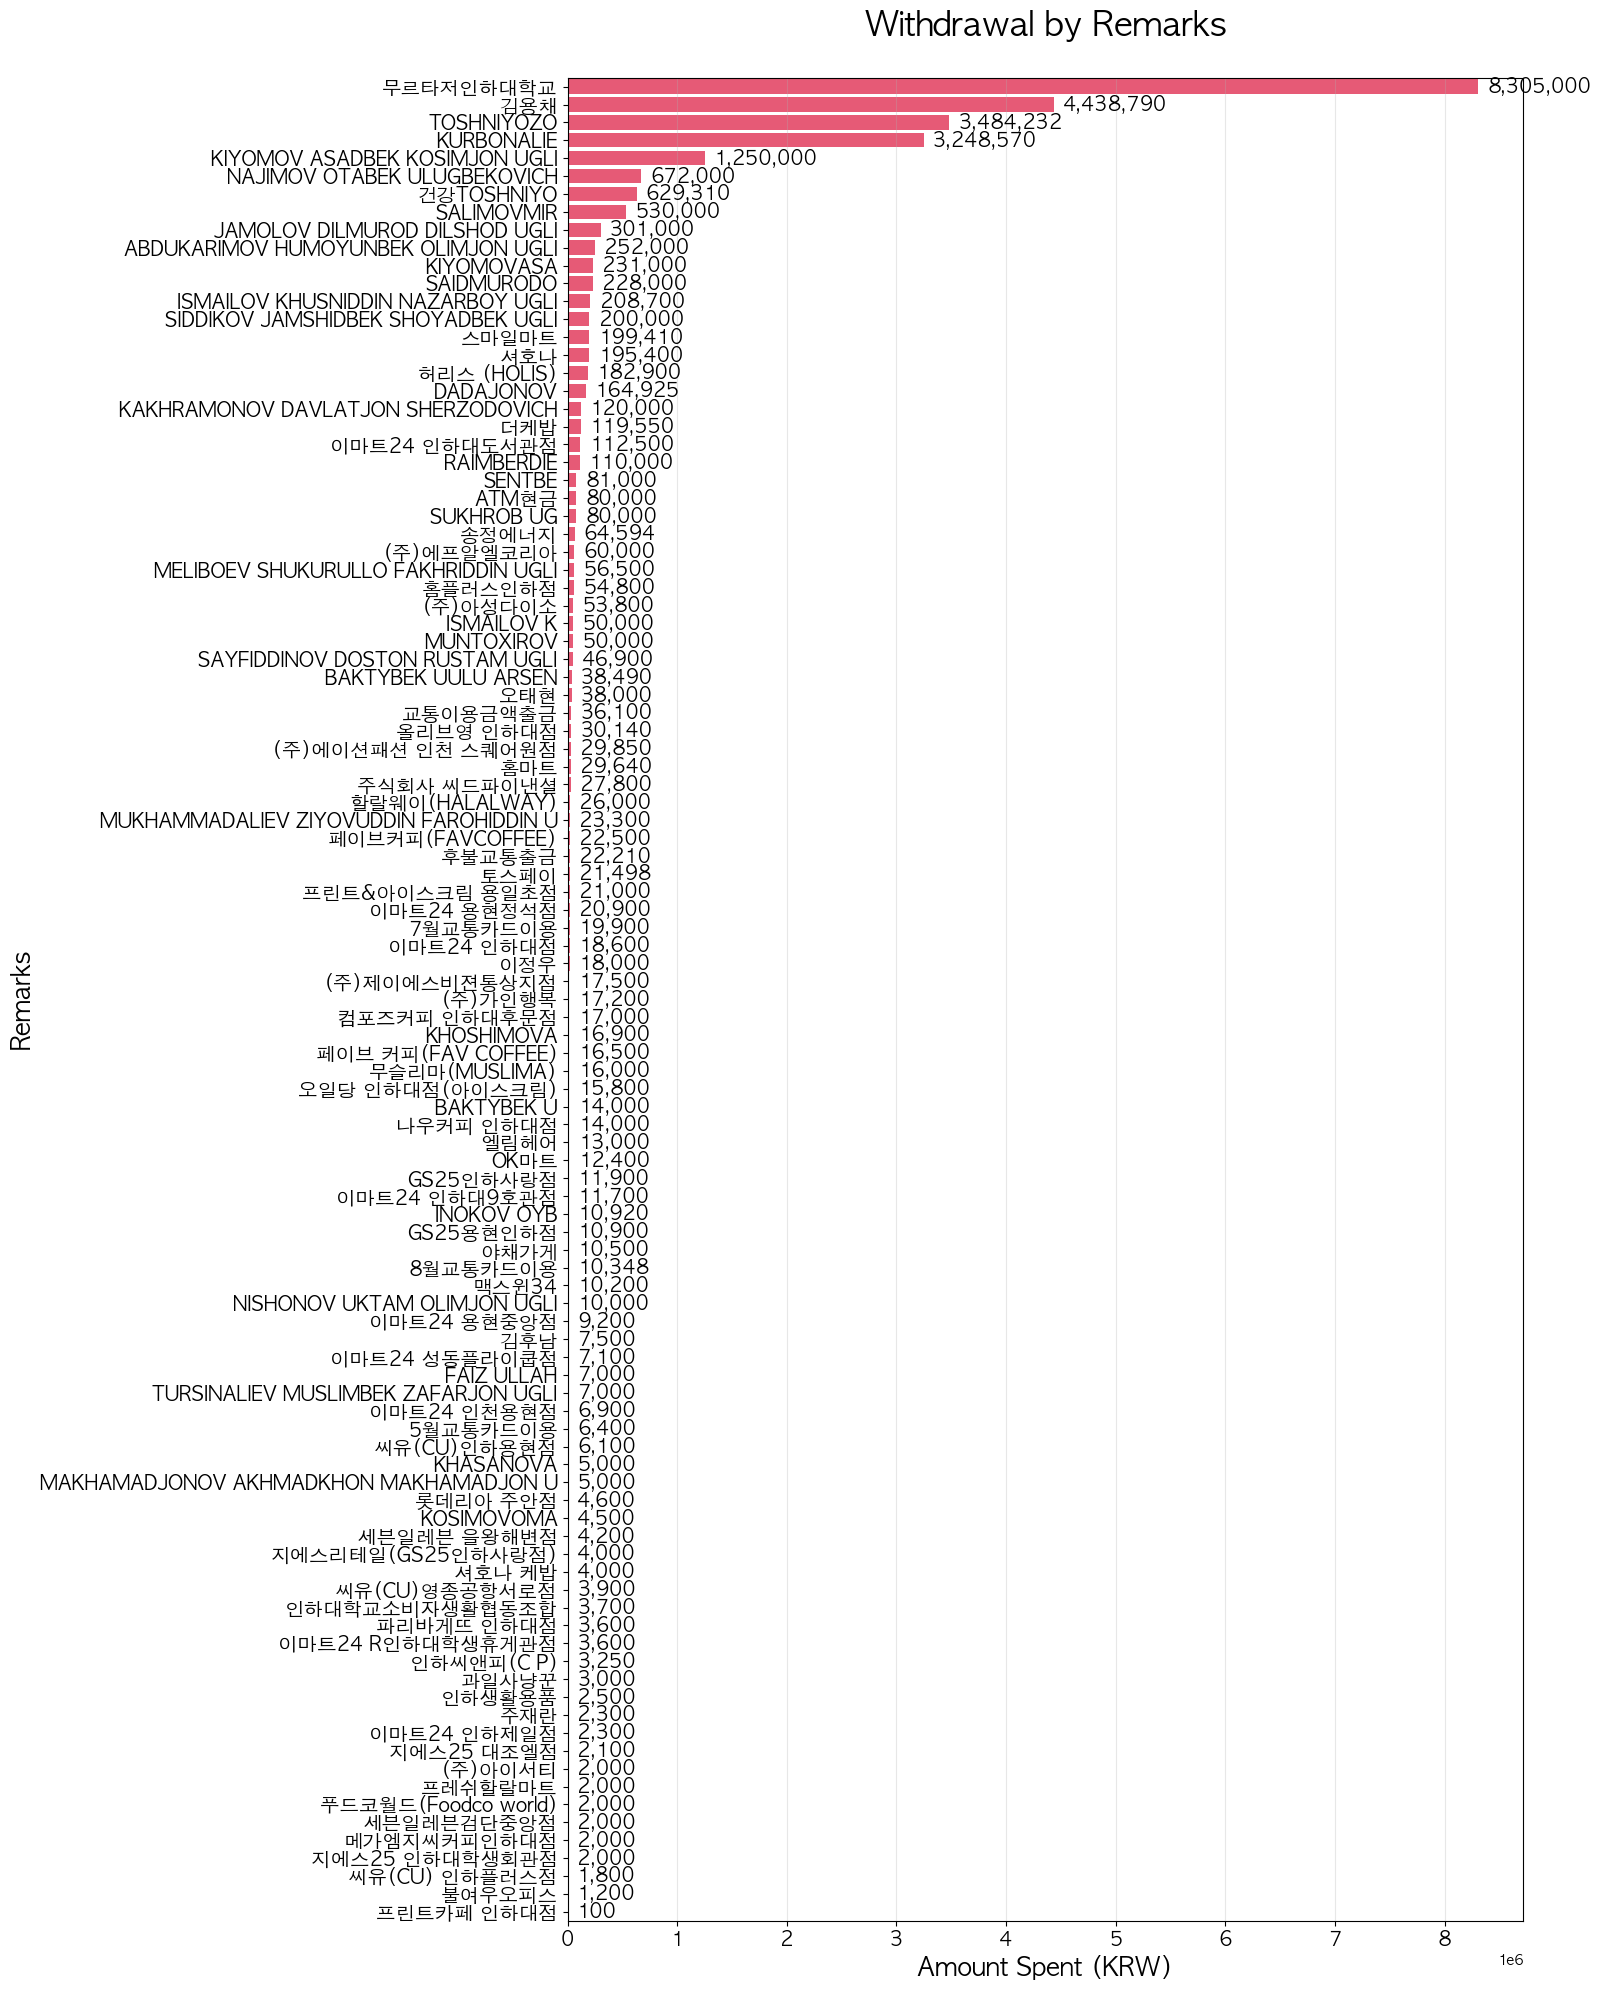

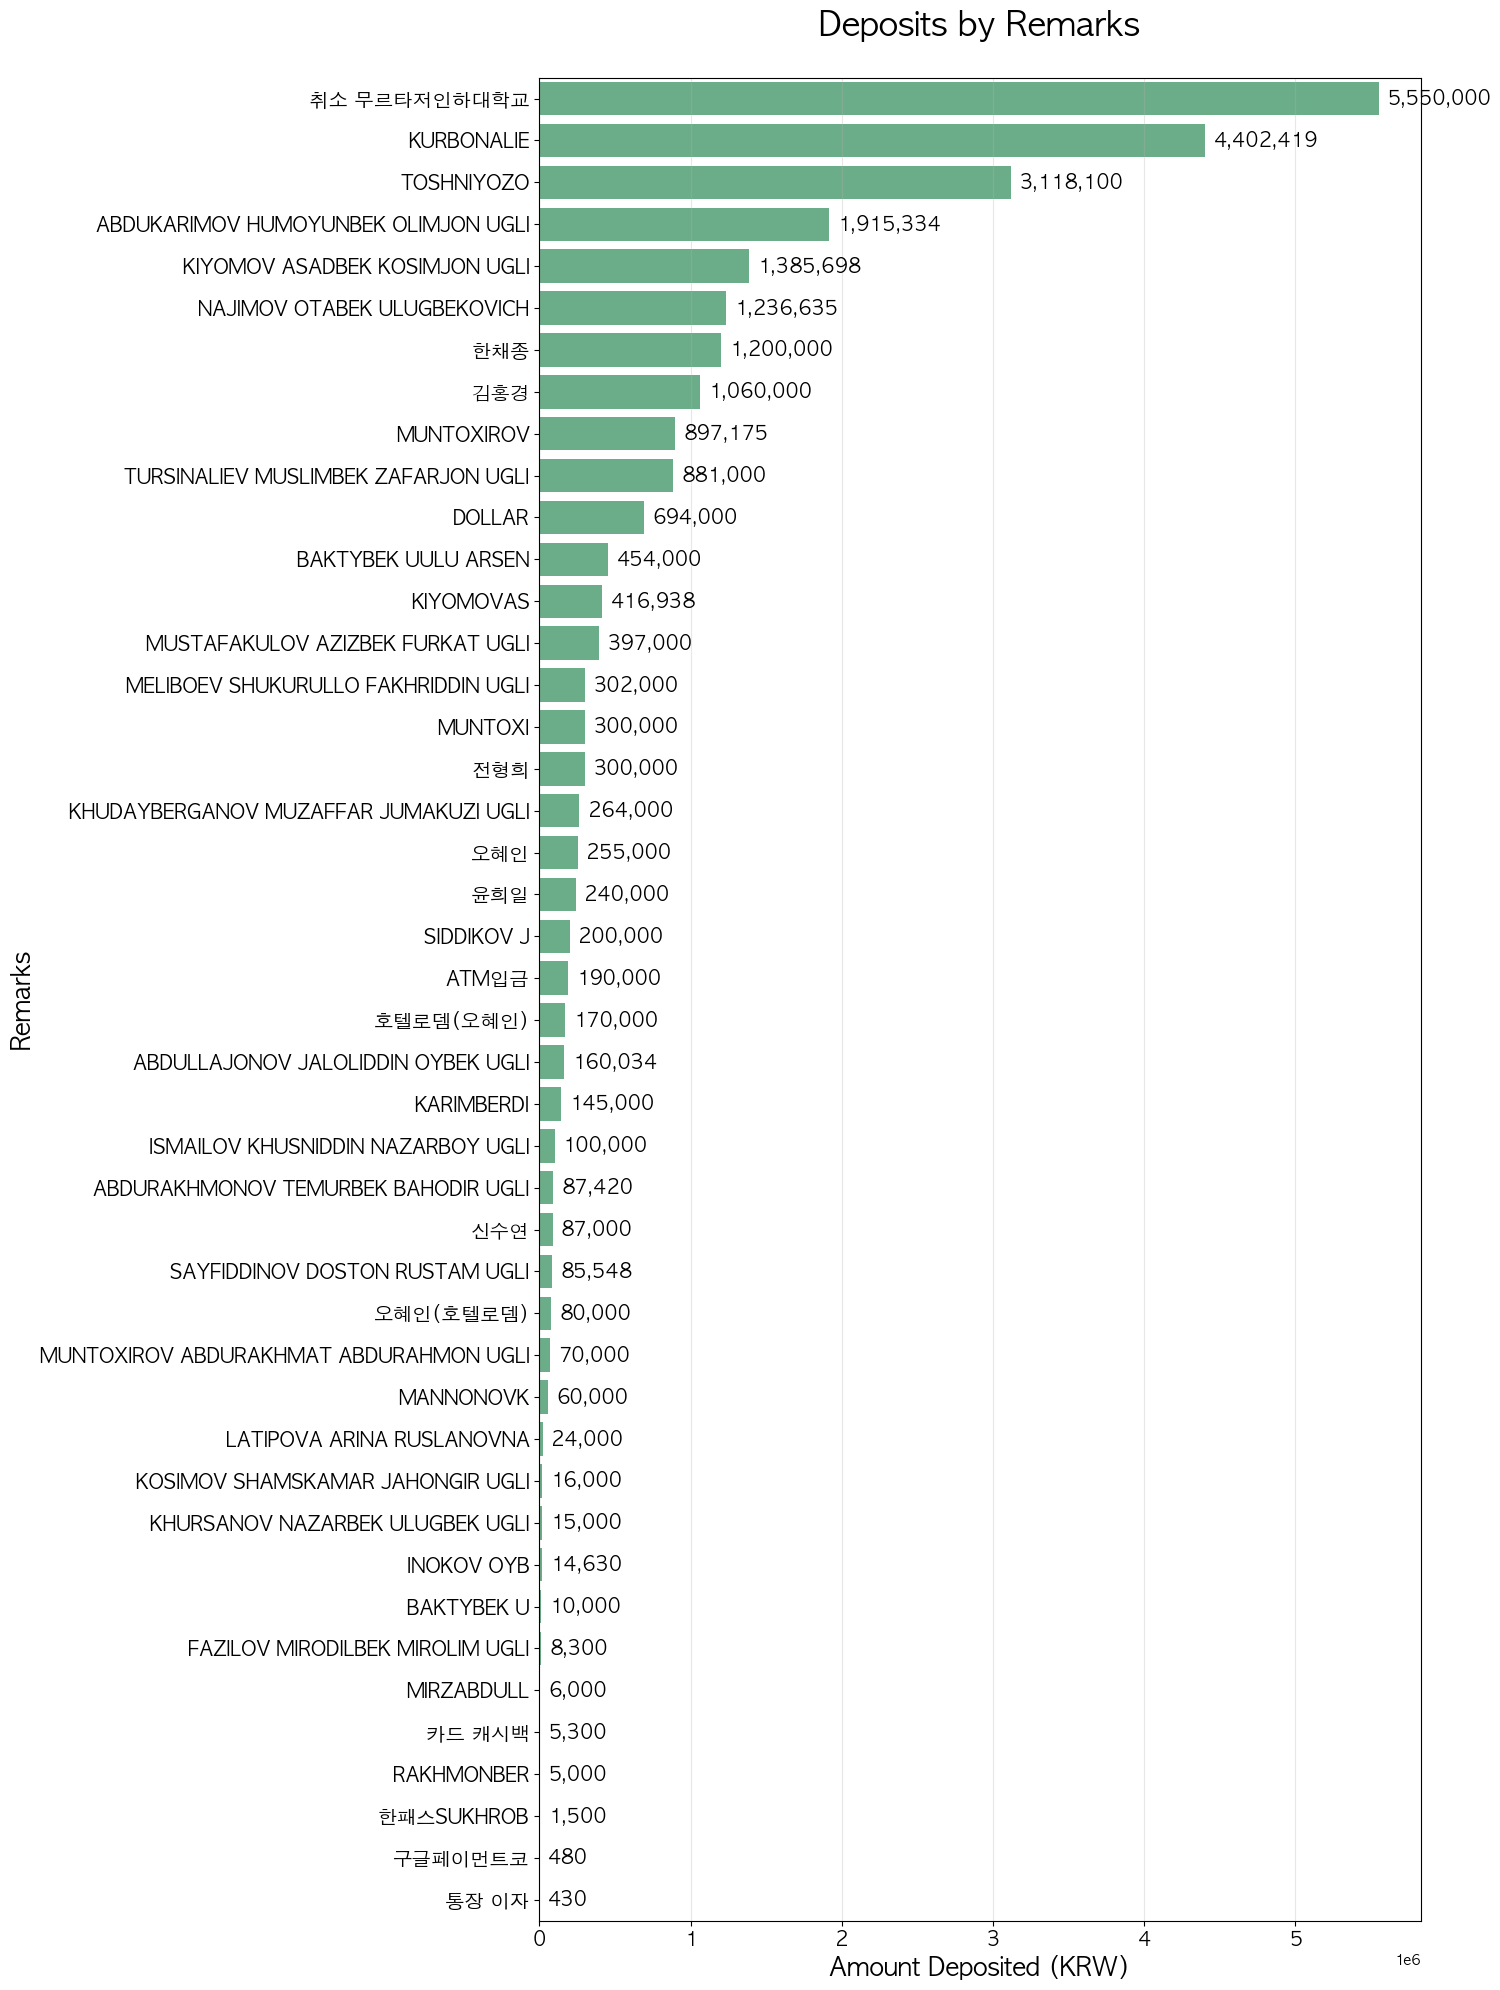

In [48]:
import pandas as pd
import matplotlib.pyplot as plt

# Korean font setup for macOS
plt.rcParams['font.family'] = ['AppleGothic', 'Arial Unicode MS']
plt.rcParams['axes.unicode_minus'] = False


# Read and prepare the data (common part)
df = pd.read_csv('transactions.csv')
df['Transaction_Amount'] = pd.to_numeric(df['Transaction_Amount'])

# Chart 1: Negative amounts (expenses)
expenses_df = df[df['Transaction_Amount'] < 0].copy()
expenses_df['Amount_Spent'] = abs(expenses_df['Transaction_Amount'])
remarks_spending = expenses_df.groupby('Remarks')['Amount_Spent'].sum().sort_values()

plt.figure(figsize=(16, 20))
bars = plt.barh(range(len(remarks_spending)), remarks_spending.values, color='#DC143C', alpha=0.7)
plt.title('Withdrawal by Remarks', fontsize=24, fontweight='bold', pad=30)
plt.xlabel('Amount Spent (KRW)', fontsize=18)
plt.ylabel('Remarks', fontsize=18)
plt.yticks(range(len(remarks_spending)), remarks_spending.index, fontsize=14)
plt.xticks(fontsize=14)
for i, v in enumerate(remarks_spending.values):
    plt.text(v + max(remarks_spending.values)*0.01, i, f'{int(v):,}', 
             va='center', fontweight='bold', fontsize=14)
plt.gca().set_ylim(-0.5, len(remarks_spending) - 0.5)
plt.grid(True, alpha=0.3, axis='x')
plt.tight_layout()
plt.savefig('visuals/spending_by_remarks_negative.png', dpi=300, bbox_inches='tight')
plt.show()

# Chart 2: Positive amounts
deposits_df = df[df['Transaction_Amount'] >= 0].copy()
remarks_deposits = deposits_df.groupby('Remarks')['Transaction_Amount'].sum().sort_values()

plt.figure(figsize=(15, 20))
bars = plt.barh(range(len(remarks_deposits)), remarks_deposits.values, color='#2E8B57', alpha=0.7)
plt.title('Deposits by Remarks', fontsize=24, fontweight='bold', pad=30)
plt.xlabel('Amount Deposited (KRW)', fontsize=18)
plt.ylabel('Remarks', fontsize=18)
plt.yticks(range(len(remarks_deposits)), remarks_deposits.index, fontsize=14)
plt.xticks(fontsize=14)
for i, v in enumerate(remarks_deposits.values):
    plt.text(v + max(remarks_deposits.values)*0.01, i, f'{int(v):,}', 
             va='center', fontweight='bold', fontsize=14)
plt.gca().set_ylim(-0.5, len(remarks_deposits) - 0.5)
plt.grid(True, alpha=0.3, axis='x')
plt.tight_layout()
plt.savefig('visuals/spending_by_remarks_positive.png', dpi=300, bbox_inches='tight')
plt.show()

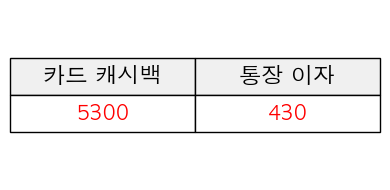

In [49]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv('transactions.csv')

total_cashback = df[df['Remarks'] == '카드 캐시백']['Transaction_Amount'].sum()
total_interest = df[df['Remarks'] == '통장 이자']['Transaction_Amount'].sum()

# Create the data
data = {'카드 캐시백': [total_cashback], '통장 이자': [total_interest]}
tb = pd.DataFrame(data)

# Create a figure and axis
fig, ax = plt.subplots(figsize=(4,2))
ax.axis('off')  # remove axes

# Create table
table = ax.table(cellText=tb.values,
                 colLabels=tb.columns,
                 cellLoc='center',
                 colLoc='center',
                 loc='center')

# Style the table
table.auto_set_font_size(False)
table.set_fontsize(14)
table.scale(1, 2)  # scale height for better appearance

# Make headers bold and red
for (row, col), cell in table.get_celld().items():
    if row == 0:  # header row
        cell.set_text_props(weight='bold', color='black', fontsize=16)
        cell.set_facecolor('#f0f0f0')  # light gray background
    else:
        cell.set_text_props(weight='bold', color='red', fontsize=14)

plt.tight_layout()
plt.savefig('visuals/cashback_and_interest.png', dpi=300, bbox_inches='tight')
plt.show()


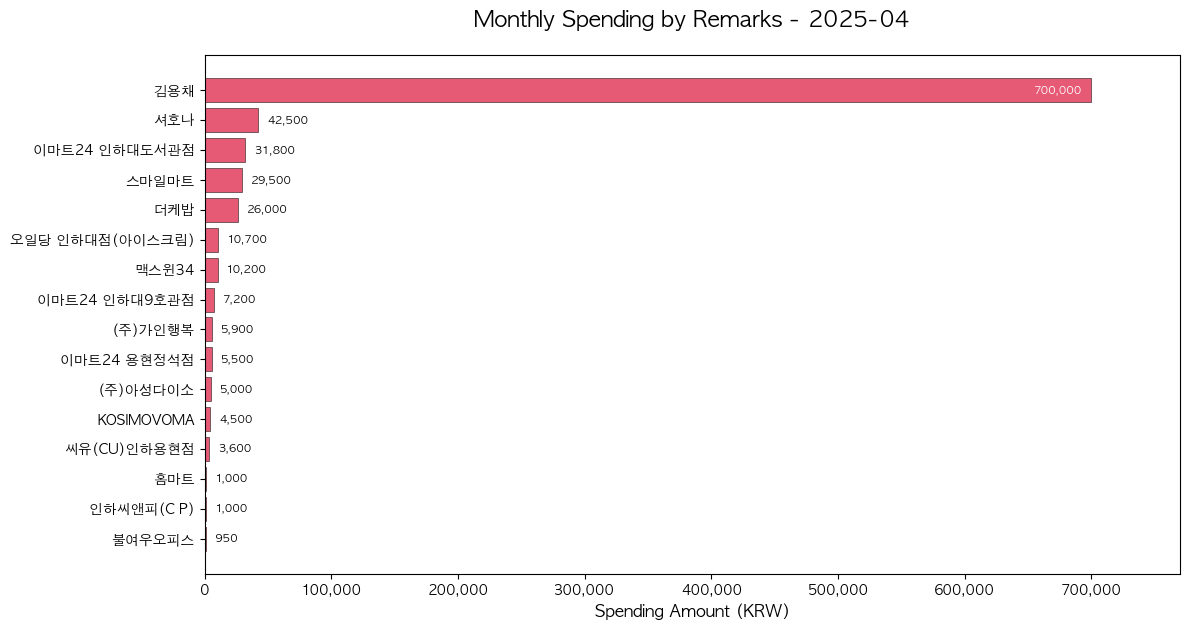

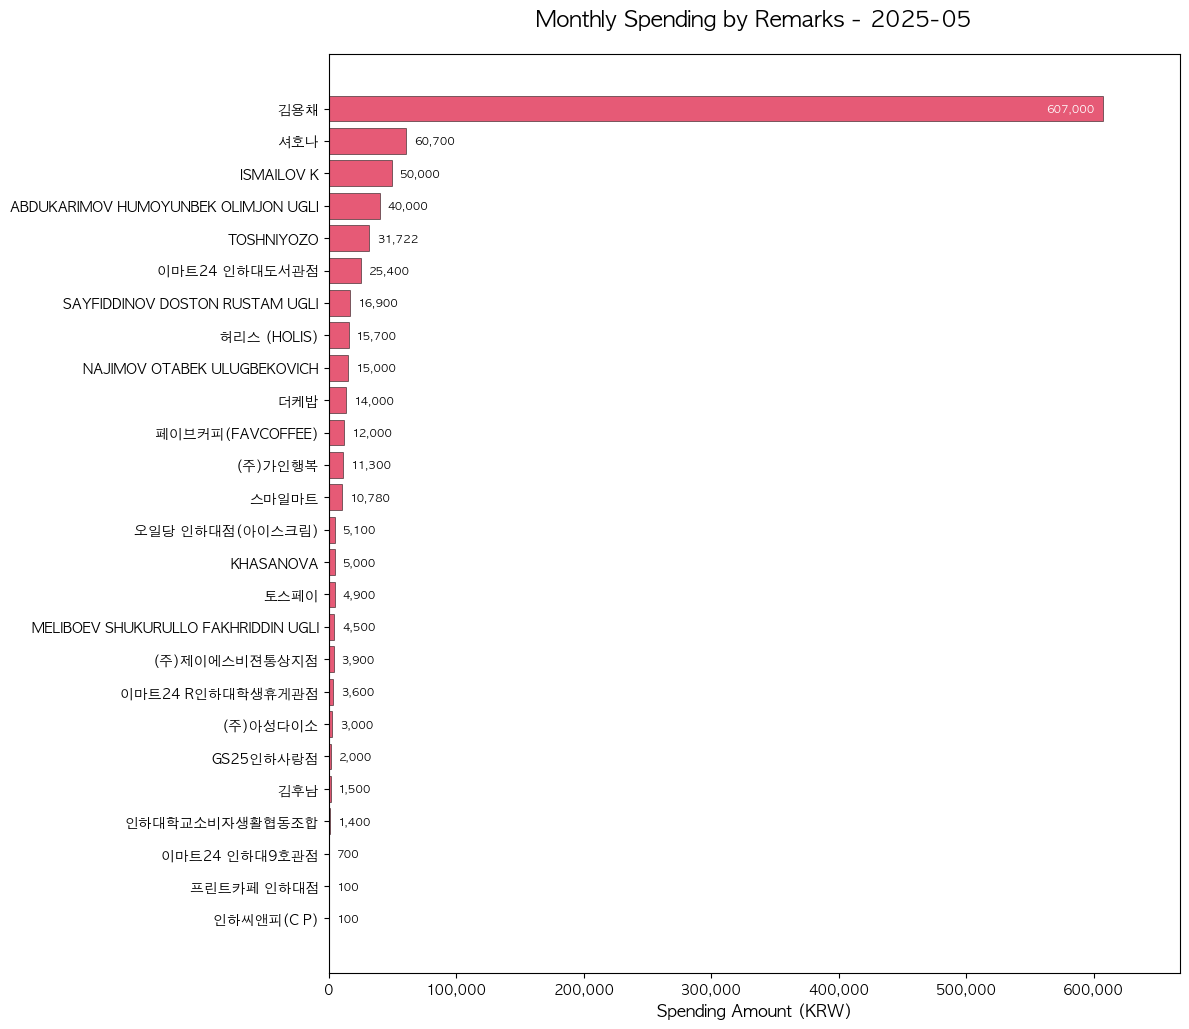

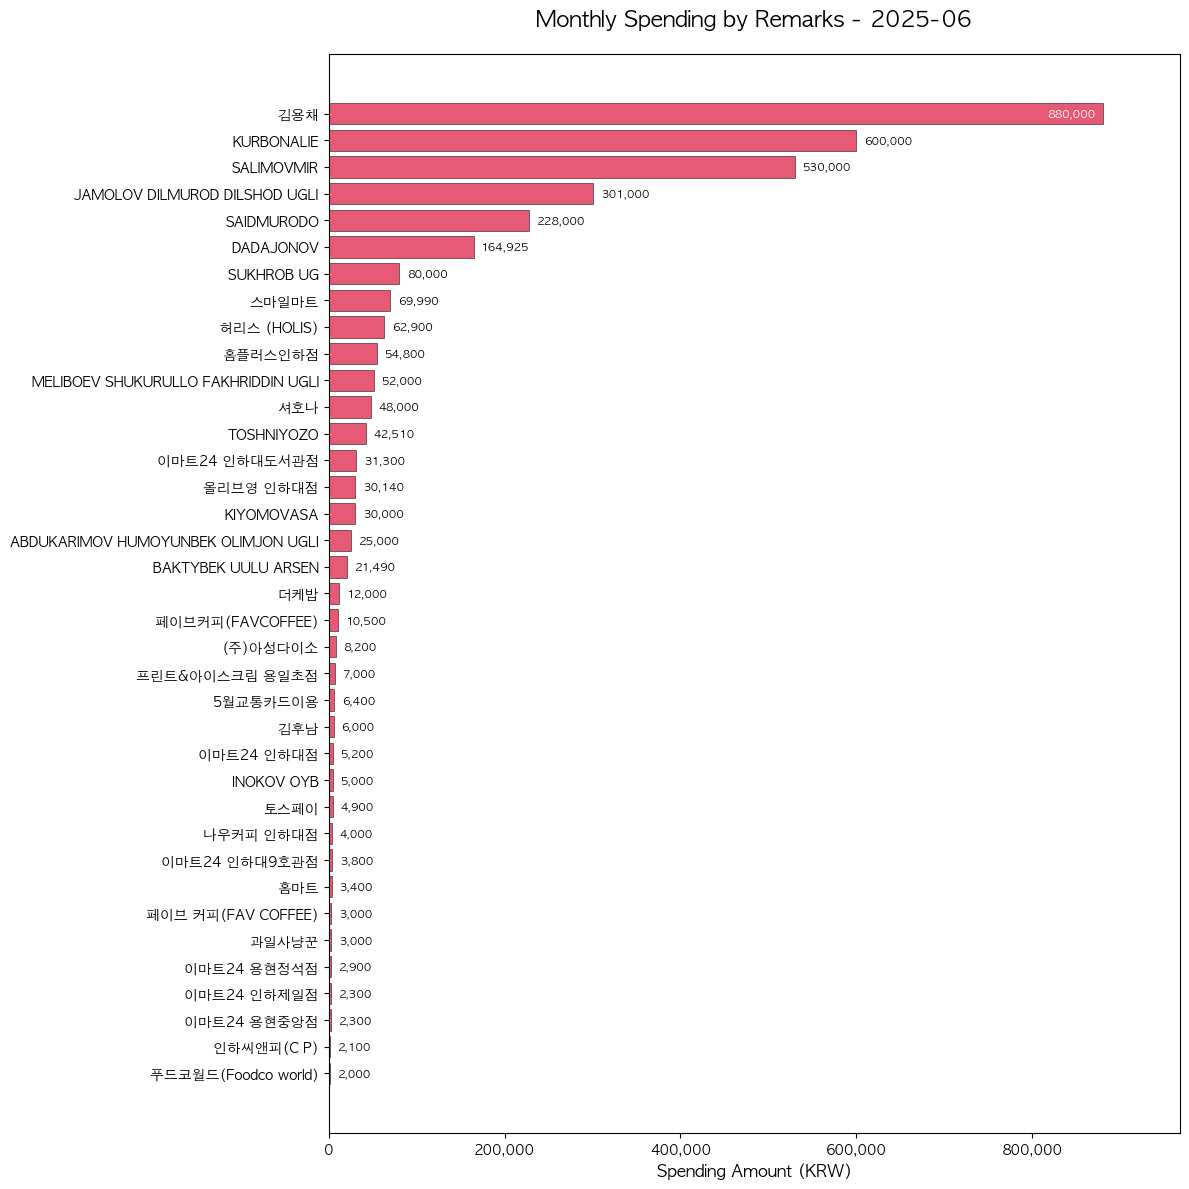

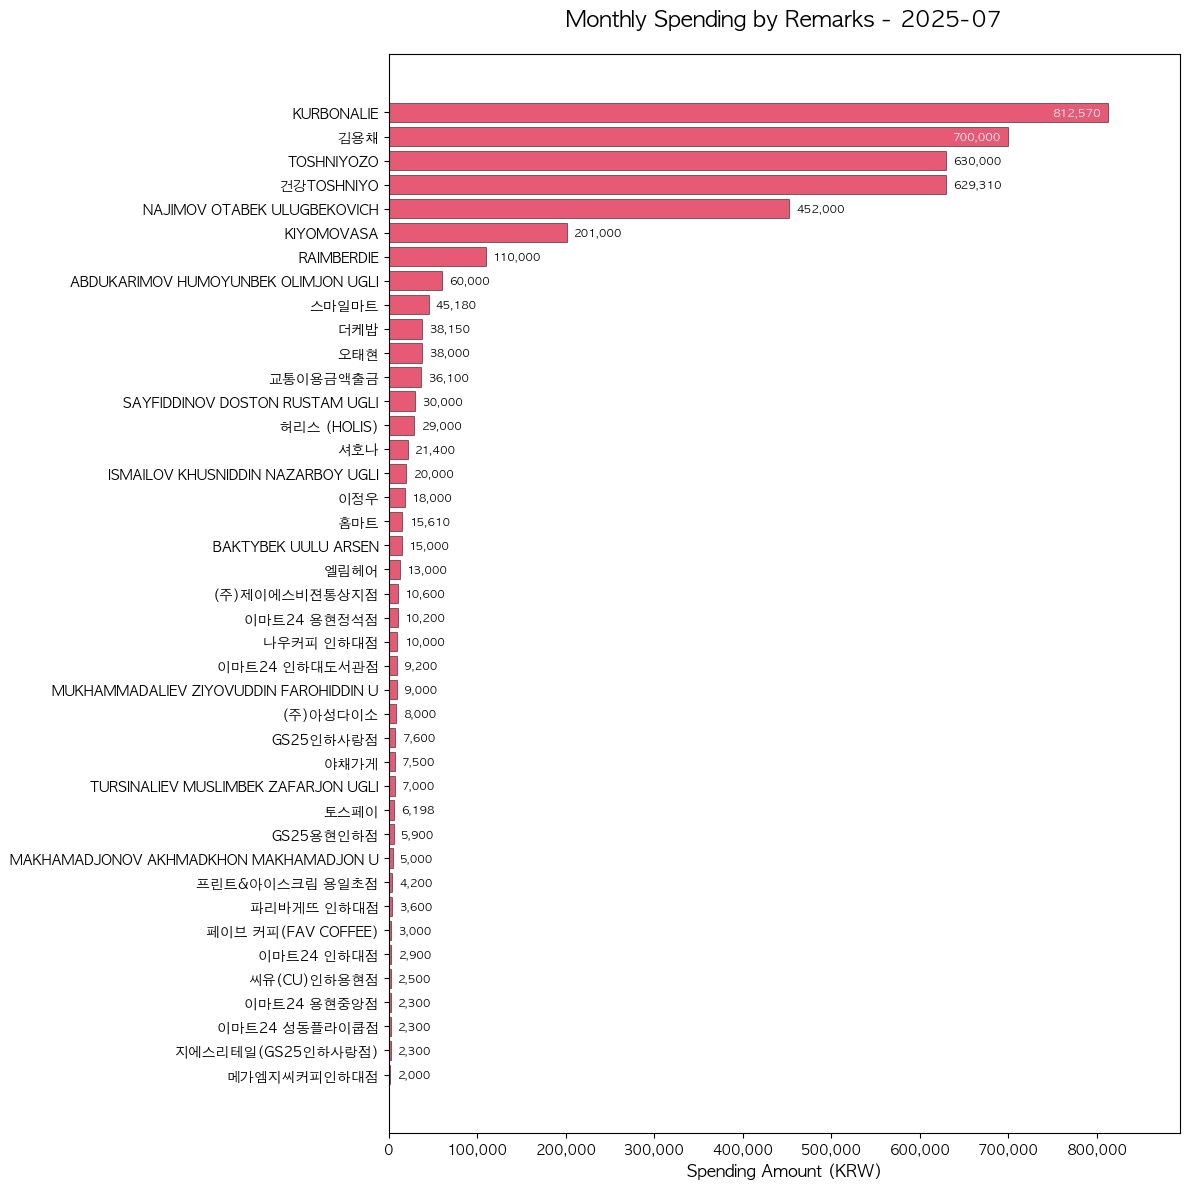

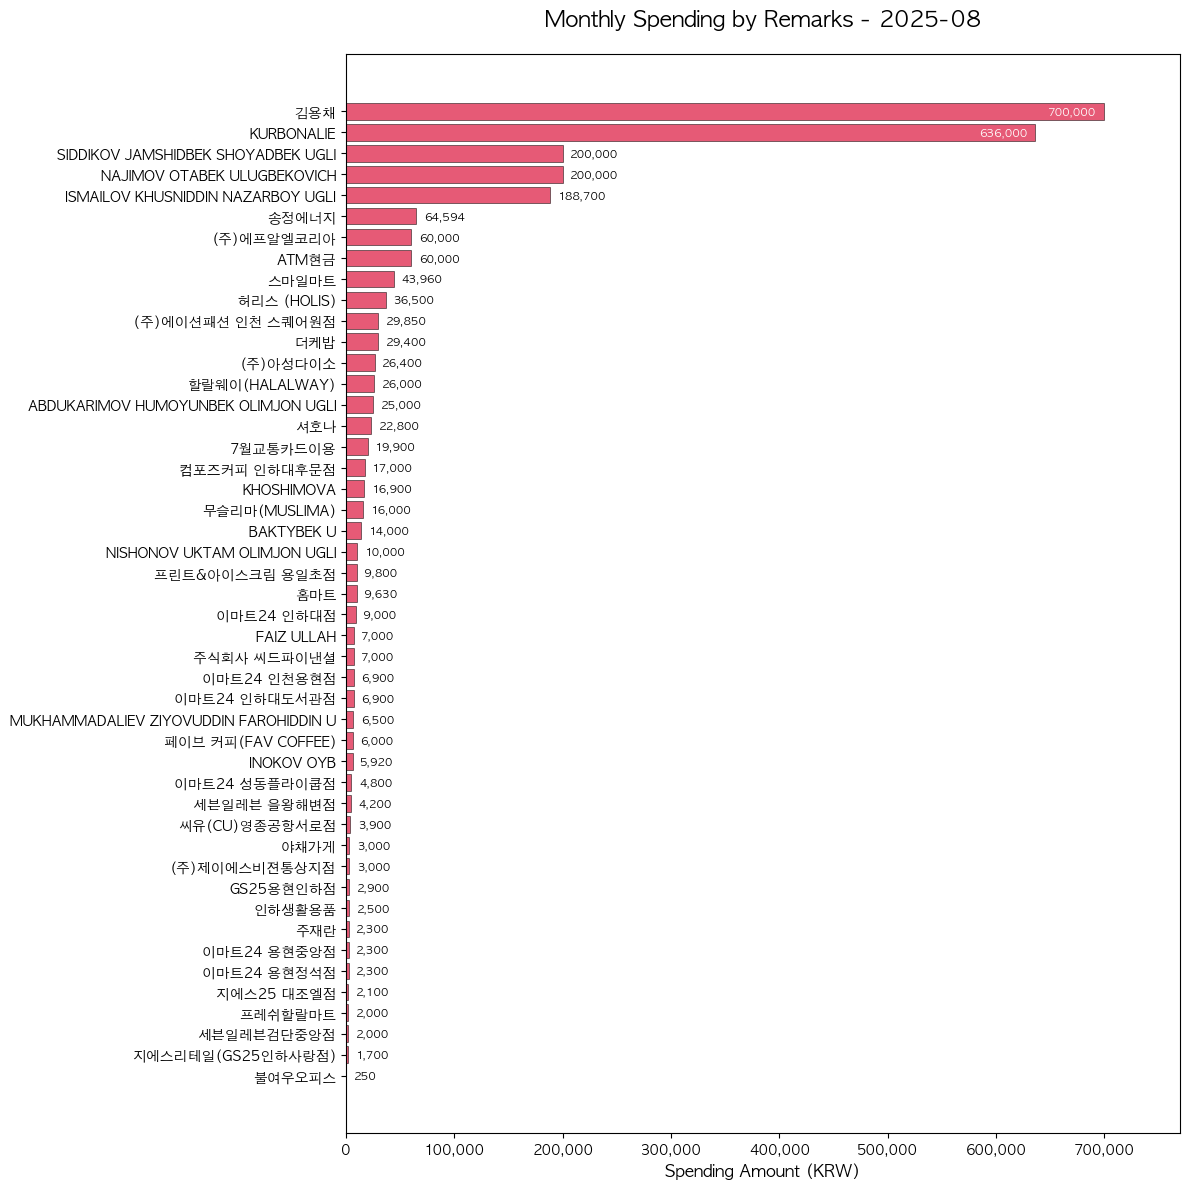

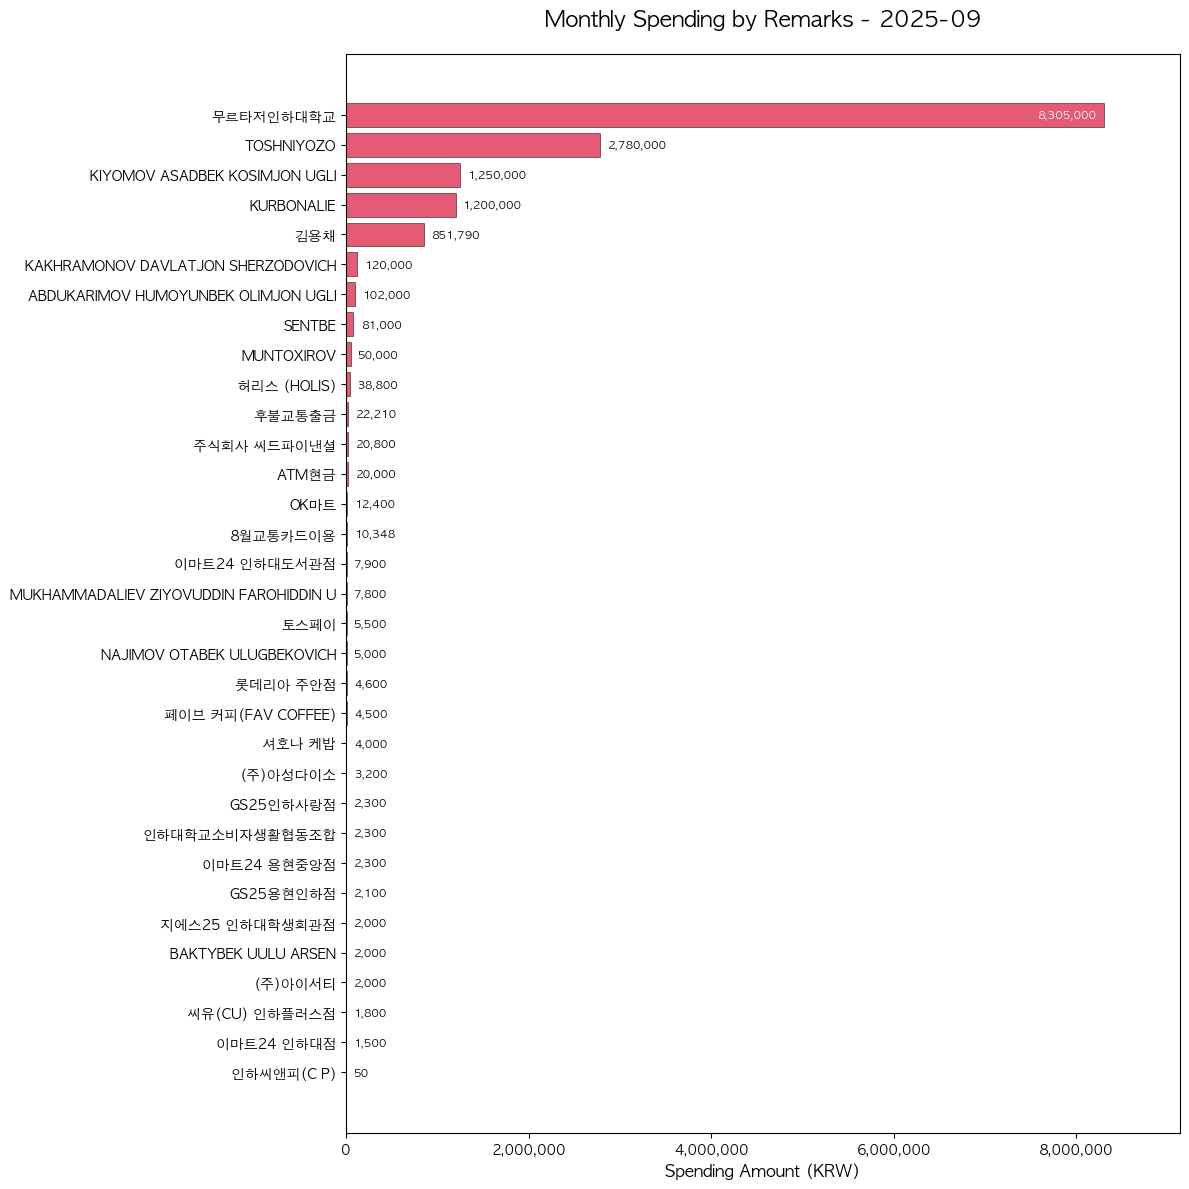

In [50]:
import pandas as pd
import matplotlib.pyplot as plt 
import os
import numpy as np


# Read data
df = pd.read_csv('transactions.csv')

# Korean font setup for macOS
plt.rcParams['font.family'] = ['AppleGothic', 'Arial Unicode MS']
plt.rcParams['axes.unicode_minus'] = False

# Parse dates and create month column
df['DateTime'] = pd.to_datetime(df['Date'] + ' ' + df['Time'])
df['Month'] = df['DateTime'].dt.to_period('M')

# Focus on spending (negative amounts for expenses)
spending_df = df[df['Transaction_Amount'] < 0].copy()
spending_df['Amount_Abs'] = spending_df['Transaction_Amount'].abs()

# Get all unique months
months = sorted(spending_df['Month'].unique())

# Function to create horizontal bar chart for each month
# def create_monthly_spending_chart(month_data, month_str):
#     """Create horizontal bar chart for monthly spending by remarks"""
    
#     # Group by remarks and sum spending
#     monthly_spending = month_data.groupby('Remarks')['Amount_Abs'].sum().sort_values(ascending=True)
    
#     # Create figure
#     fig, ax = plt.subplots(figsize=(12, max(8, len(monthly_spending) * 0.4)))
    
#     # Create horizontal bar chart
#     bars = ax.barh(range(len(monthly_spending)), monthly_spending.values, 
#                    color='#DC143C', alpha=0.7, edgecolor='black', linewidth=0.5)
    
#     # Customize chart
#     ax.set_yticks(range(len(monthly_spending)))
#     ax.set_yticklabels(monthly_spending.index, fontsize=10)
#     ax.set_xlabel('Spending Amount (KRW)', fontsize=12, fontweight='bold')
#     ax.set_title(f'Monthly Spending by Remarks - {month_str}', 
#                 fontsize=16, fontweight='bold', pad=20)
    
#     # Add value labels on bars
#     for i, (bar, value) in enumerate(zip(bars, monthly_spending.values)):
#         ax.text(value + max(monthly_spending.values) * 0.01, i, 
#                f'{value:,.0f}', 
#                va='center', ha='left', fontsize=8, fontweight='bold')
    
#     # # Add grid for better readability
#     # ax.grid(axis='x', alpha=0.3, linestyle='--')
#     # ax.set_axisbelow(True)
    
#     # Format x-axis
#     ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f'{x:,.0f}'))
    
#     # Add total spending text
#     total_monthly = monthly_spending.sum()
    
    
#     plt.tight_layout()
    
#     # Save individual month chart
#     filename = f'visuals/monthly_spending_by_remarks/spending_by_remarks_{month_str}.png'
#     plt.savefig(filename, dpi=300, bbox_inches='tight', facecolor='white')
#     plt.show()
    
#     return monthly_spending, total_monthly

def create_monthly_spending_chart(month_data, month_str):
    # Group by remarks and sum spending
    monthly_spending = (
        month_data.groupby('Remarks')['Amount_Abs']
        .sum()
        .sort_values(ascending=True)
    )

    # --- Dynamic figure size ---
    n = len(monthly_spending)
    fig_height = max(6, min(12, n * 0.4))  # flexible height, but capped
    fig, ax = plt.subplots(figsize=(12, fig_height))

    # --- Create horizontal bar chart ---
    bars = ax.barh(
        range(n),
        monthly_spending.values,
        color='#DC143C',
        alpha=0.7,
        edgecolor='black',
        linewidth=0.5,
    )

    # --- Y-axis ---
    ax.set_yticks(range(n))
    ax.set_yticklabels(monthly_spending.index, fontsize=10)

    # --- X-axis ---
    ax.set_xlabel('Spending Amount (KRW)', fontsize=12, fontweight='bold')
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f'{x:,.0f}'))

    # --- Title ---
    ax.set_title(
        f'Monthly Spending by Remarks - {month_str}',
        fontsize=16,
        fontweight='bold',
        pad=20,
    )

    # --- Add value labels inside bars if too long, else outside ---
    max_val = monthly_spending.values.max()
    for i, (bar, value) in enumerate(zip(bars, monthly_spending.values)):
        text_offset = max_val * 0.01
        if value > max_val * 0.85:  # if bar is very long, put label inside
            ax.text(
                value - text_offset,
                i,
                f'{value:,.0f}',
                va='center',
                ha='right',
                fontsize=8,
                fontweight='bold',
                color='white',
            )
        else:  # otherwise put label outside
            ax.text(
                value + text_offset,
                i,
                f'{value:,.0f}',
                va='center',
                ha='left',
                fontsize=8,
                fontweight='bold',
            )

    # --- Prevent clipping ---
    ax.margins(x=0.1)  # add margin on the right so labels never get cut off

    plt.tight_layout()

    # --- Save individual month chart ---
    filename = f'visuals/monthly_spending_by_remarks/spending_byremarks{month_str}.png'
    plt.savefig(filename, dpi=300, bbox_inches='tight', facecolor='white')
    plt.show()

    return monthly_spending, monthly_spending.sum()

for month in months:
    month_data = spending_df[spending_df['Month'] == month]
    month_str = str(month)
    result = create_monthly_spending_chart(month_data, month_str)



--- Processing 2025-04 ---
Deposit Transactions: 17


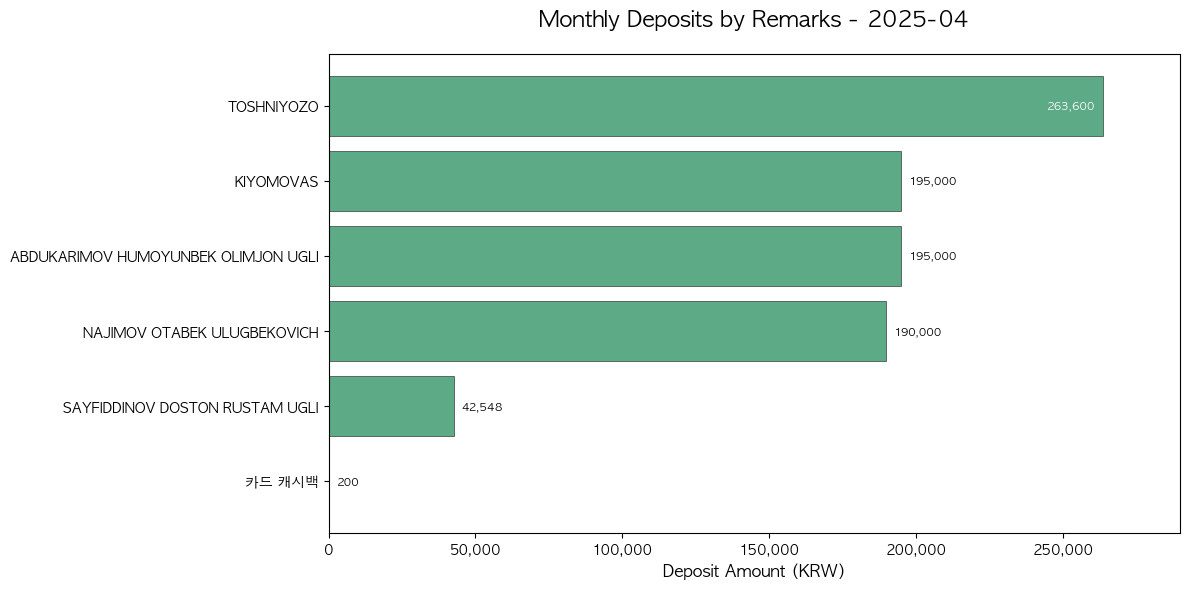

Total Deposits: 886,348 KRW
Top Deposit Source: TOSHNIYOZO (263,600 KRW)

--- Processing 2025-05 ---
Deposit Transactions: 16


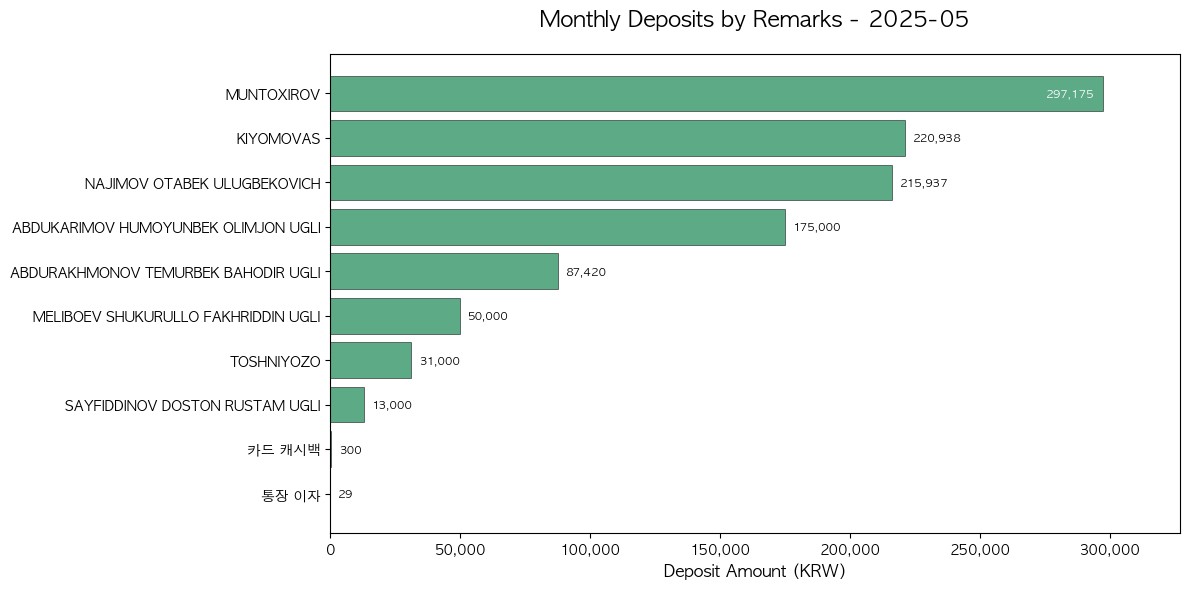

Total Deposits: 1,090,799 KRW
Top Deposit Source: MUNTOXIROV (297,175 KRW)

--- Processing 2025-06 ---
Deposit Transactions: 39


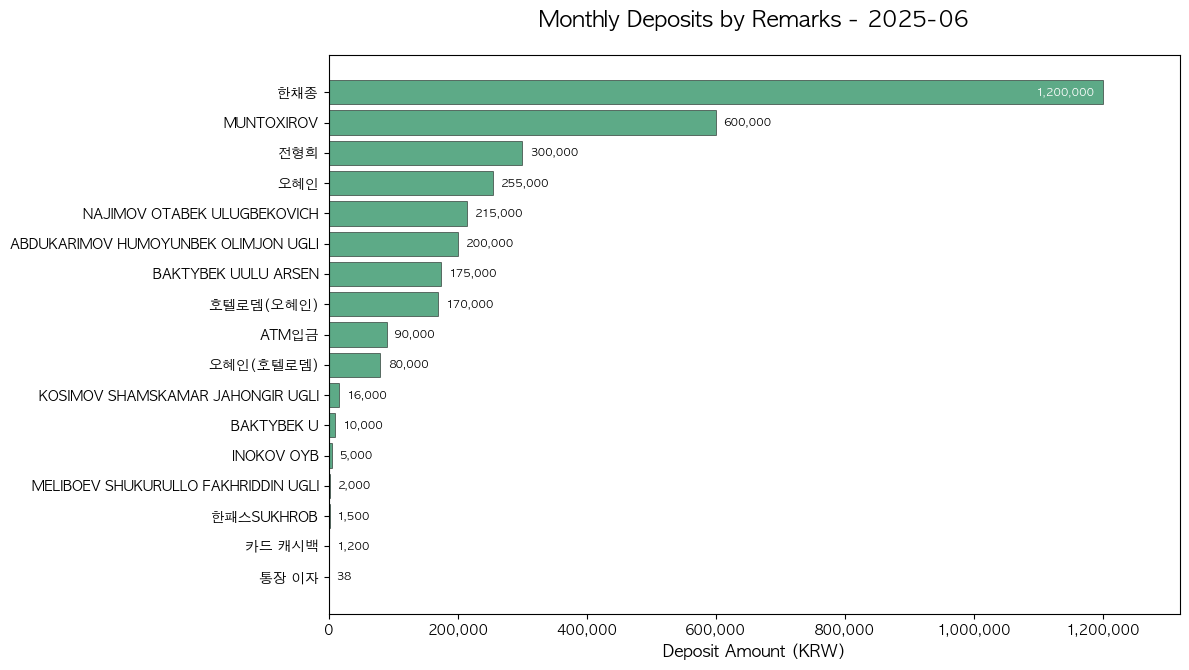

Total Deposits: 3,320,738 KRW
Top Deposit Source: 한채종 (1,200,000 KRW)

--- Processing 2025-07 ---
Deposit Transactions: 35


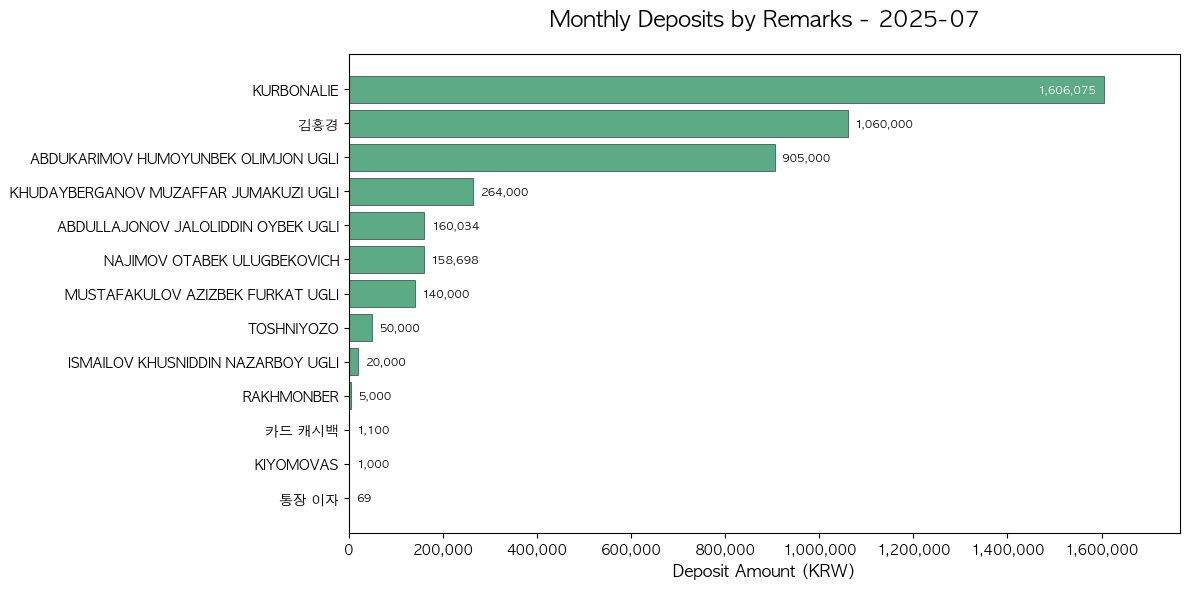

Total Deposits: 4,370,976 KRW
Top Deposit Source: KURBONALIE (1,606,075 KRW)

--- Processing 2025-08 ---
Deposit Transactions: 36


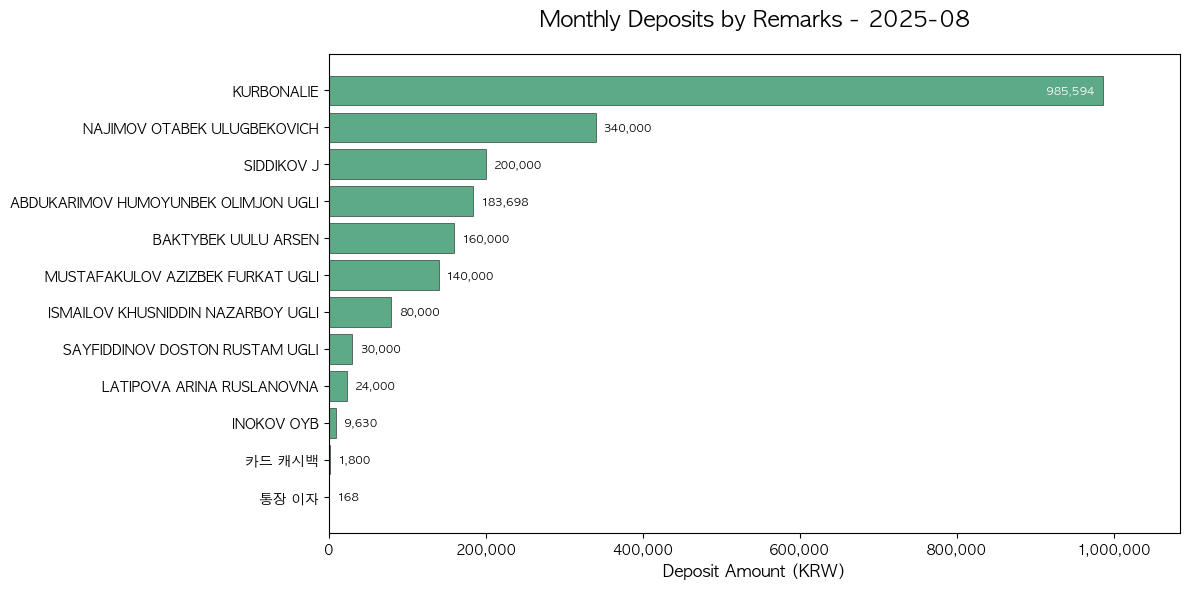

Total Deposits: 2,154,890 KRW
Top Deposit Source: KURBONALIE (985,594 KRW)

--- Processing 2025-09 ---
Deposit Transactions: 48


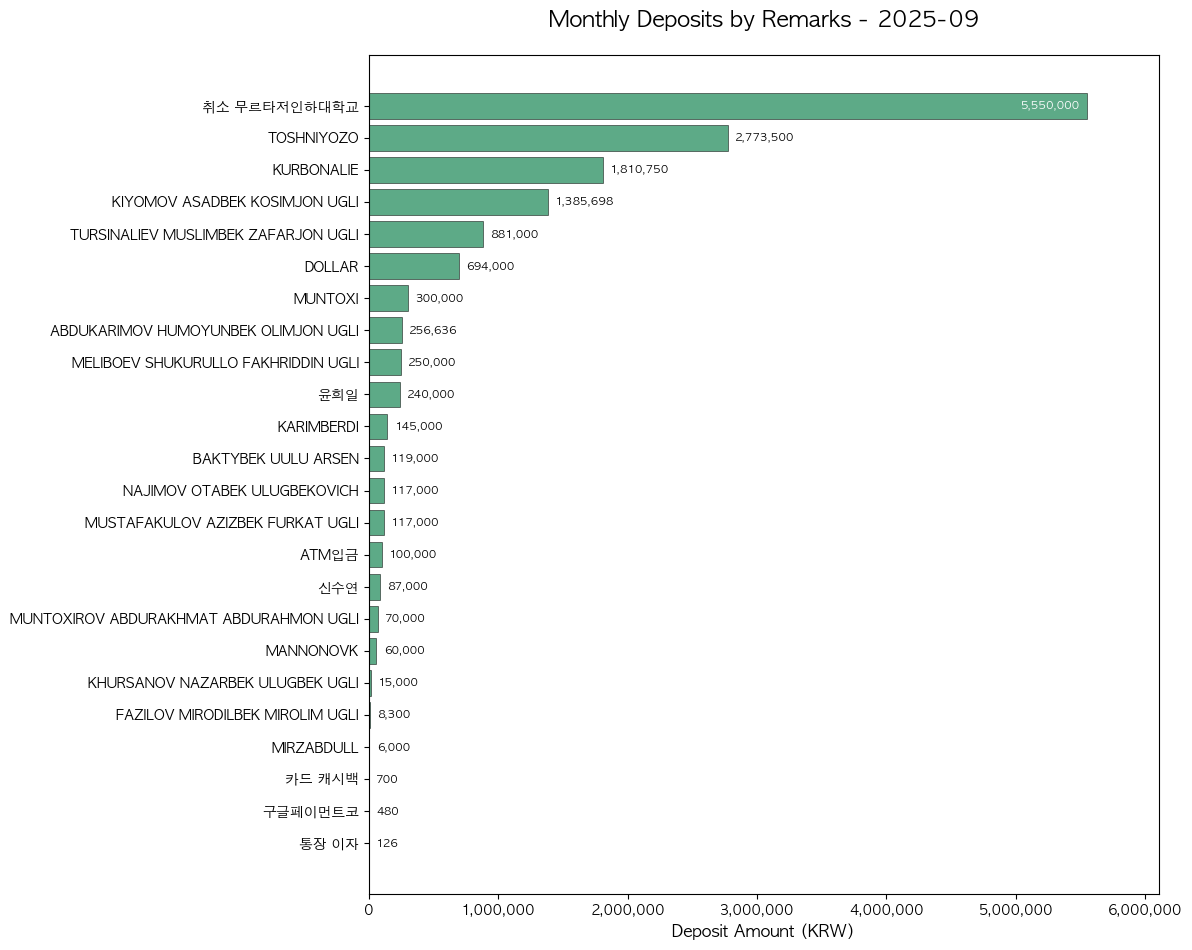

Total Deposits: 14,987,190 KRW
Top Deposit Source: 취소 무르타저인하대학교 (5,550,000 KRW)


In [51]:
import pandas as pd
import matplotlib.pyplot as plt 
import os
import numpy as np

# Read data
df = pd.read_csv('transactions.csv')

# Korean font setup for macOS
plt.rcParams['font.family'] = ['AppleGothic', 'Arial Unicode MS']
plt.rcParams['axes.unicode_minus'] = False

# Parse dates and create month column
df['DateTime'] = pd.to_datetime(df['Date'] + ' ' + df['Time'])
df['Month'] = df['DateTime'].dt.to_period('M')

# Focus on deposits/income (positive amounts)
deposits_df = df[df['Transaction_Amount'] > 0].copy()

# print("=== MONTHLY DEPOSITS BY REMARKS ANALYSIS ===")
# print(f"Date Range: {df['DateTime'].min().strftime('%Y-%m-%d')} to {df['DateTime'].max().strftime('%Y-%m-%d')}")
# print(f"Total Deposit Transactions: {len(deposits_df)}")

# Get all unique months
months = sorted(deposits_df['Month'].unique())
# print(f"Months Covered: {len(months)} months")

# Create visuals directory if it doesn't exist
os.makedirs('visuals/monthly_deposits_by_remarks', exist_ok=True)

def create_monthly_deposits_chart(month_data, month_str):
    """Create horizontal bar chart for monthly deposits by remarks"""
    
    # Group by remarks and sum deposits
    monthly_deposits = (
        month_data.groupby('Remarks')['Transaction_Amount']
        .sum()
        .sort_values(ascending=True)
    )

    # Dynamic figure size
    n = len(monthly_deposits)
    fig_height = max(6, min(12, n * 0.4))  # flexible height, but capped
    fig, ax = plt.subplots(figsize=(12, fig_height))

    # Create horizontal bar chart with green color
    bars = ax.barh(
        range(n),
        monthly_deposits.values,
        color='#198754',  # Dark green for deposits
        alpha=0.7,
        edgecolor='black',
        linewidth=0.5,
    )

    # Y-axis
    ax.set_yticks(range(n))
    ax.set_yticklabels(monthly_deposits.index, fontsize=10)

    # X-axis
    ax.set_xlabel('Deposit Amount (KRW)', fontsize=12, fontweight='bold')
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f'{x:,.0f}'))

    # Title
    ax.set_title(
        f'Monthly Deposits by Remarks - {month_str}',
        fontsize=16,
        fontweight='bold',
        pad=20,
    )

    # Add value labels inside bars if too long, else outside
    max_val = monthly_deposits.values.max()
    for i, (bar, value) in enumerate(zip(bars, monthly_deposits.values)):
        text_offset = max_val * 0.01
        if value > max_val * 0.85:  # if bar is very long, put label inside
            ax.text(
                value - text_offset,
                i,
                f'{value:,.0f}',
                va='center',
                ha='right',
                fontsize=8,
                fontweight='bold',
                color='white',
            )
        else:  # otherwise put label outside
            ax.text(
                value + text_offset,
                i,
                f'{value:,.0f}',
                va='center',
                ha='left',
                fontsize=8,
                fontweight='bold',
            )

    # Prevent clipping
    ax.margins(x=0.1)  # add margin on the right so labels never get cut off

    plt.tight_layout()

    # Save individual month chart
    filename = f'visuals/monthly_deposits_by_remarks/deposits_by_remarks_{month_str}.png'
    plt.savefig(filename, dpi=300, bbox_inches='tight', facecolor='white')
    plt.show()

    return monthly_deposits, monthly_deposits.sum()

# Process each month and create individual charts
monthly_totals = {}
all_monthly_data = {}

for month in months:
    month_data = deposits_df[deposits_df['Month'] == month]
    month_str = str(month)
    
    print(f"\n--- Processing {month_str} ---")
    print(f"Deposit Transactions: {len(month_data)}")
    
    if len(month_data) > 0:
        result = create_monthly_deposits_chart(month_data, month_str)
        monthly_deposits, total_monthly = result
        monthly_totals[month_str] = total_monthly
        all_monthly_data[month_str] = monthly_deposits
        print(f"Total Deposits: {total_monthly:,.0f} KRW")
        print(f"Top Deposit Source: {monthly_deposits.index[-1]} ({monthly_deposits.iloc[-1]:,.0f} KRW)")
    else:
        print("No deposits found for this month")


In [3]:
import pandas as pd
df = pd.read_csv('transactions.csv', parse_dates=['Date', 'Time'])
df.dtypes

/var/folders/94/y14zllwx001_mnk6qm5z5w3c0000gn/T/ipykernel_71981/1422025398.py:2: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df = pd.read_csv('transactions.csv', parse_dates=['Date', 'Time'])


Date                  datetime64[ns]
Time                  datetime64[ns]
Remarks                       object
Transaction_Type              object
Bank_Name                     object
Account_Number                 int64
Transaction_Amount             int64
Balance                      float64
dtype: object